# Build the best Toffoli gate you can

Your team will submit a quantum circuit which implements a Toffoli (controlled-controlled-NOT) gate using only the supplied **native** gate set. The lab will execute it on real hardware and return raw, shot-by-shot outcomes. Your aim is a Toffoli that is as accurate as you can make it, *and the evidence to show it*.

> **The final challenge: prove that your Toffoli gate is the best.** There is no leaderboard and no scoring formula. You decide what "best" should mean, which experiments make the case, and how sure you are. Sections 7 and 8 show what a truth table can and cannot tell you and point you to the tools (tomography and cheaper relatives) that go further. Section 10 describes what the judges look for.

> **Hardware window: 4:00 PM to 12:00 midnight.** The hardware queue opens at **4:00 PM** and closes at **midnight**. The relay refuses every hardware submission sent before 4:00 PM or after midnight, so nothing can be queued early and nothing can be squeezed in late. Until 4:00 PM, all of your work happens on simulators: use that time to finish and verify your circuit and to plan every hardware experiment you intend to run.
>
> **After midnight: the IonQ extension.** For the remaining 12 hours (midnight to noon) you can keep working on the same problem on IonQ's quantum cloud, with your own IonQ API key, in the IonQ extension notebook, which the organizers release at midnight. Watch for the IonQ invitation email during the evening and accept it early.


---

# Background

### What is a qubit?

The fundamental component of a classical computer is a bit. It can take values either 0 or 1. Bits can be operated on with "gates." Some examples include the AND, NOT, and XOR gates. These represent some basic building blocks that can be strung together to create complex programs. In fact, the computer you're reading on is using these bits and gates to present this text on your screen, communicate with the Internet, and many other core functionalities under the hood. 

Quantum computers similarly have a fundamental component: a quantum bit (qubits). Qubits work differently when compared to classical bits. These need not be in a definite state of 0 or 1. One can prepare a qubit to be in a state that has a *probability* of being in a state of 0 or 1. Quantum mechanics is what makes this possible. This is one core feature of quantum computing that sets it apart from classical computing. We can write a qubit's state in the following manner: $$\ket{\psi} = \alpha \ket{0} + \beta \ket{1}, \quad |\alpha|^2 + |\beta|^2 = 1, \alpha, \beta \in \mathbb{C}.$$ 

Here, $\ket \psi$ is the mathematical object (a vector!) that represents the state of qubit (i.e, a quantum state). Notice that $\alpha, \beta$ are complex-number coefficients whose *magnitudes'* squares must sum to 1. The square of the magnitude of $\alpha, \beta$ represent the probability of observing the qubit in state 0 or 1, respectively. Why the magnitude square? To fully capture the properties of quantum mechanics (namely, interference), we require the use of complex numbers. But, probabilities are strictly real numbers. We account for this by using the magnitude squared. 

Notice that when we observe a qubit, all we see is a state 0 or 1. We don't get to observe the probabilities of seeing 0 and 1. The two independent quantum states $\ket{\psi_1} = \frac{1}{\sqrt{2}}\ket 0 + \frac{1}{\sqrt{2}} \ket 1, \ket{\psi_2} = \frac{1}{\sqrt{3}}\ket 0 + \sqrt{\frac{2}{3}} \ket 1$ each have different probabilities of observing the states 0 and 1. Yet, when we measure both, we may observe both qubits being in state 0.

The way we determine the probabilities of a qubit being in each state is (1) prepare the state, (2) measure it, (3) repeat. Say you repeat this 1000 times. Then, for $\ket{\psi_1}$ you should expect half of your measurement outcomes to be 0 and the other half to be 1. For $\ket{\psi_2}$, we should expect 1/3 of all outcomes to be 0 and 2/3 of all outcomes to be 1.

We can extend this to multiple qubits as well. For instance, one can have a three-qubit state $\ket \phi = \frac{1}{\sqrt 2}\ket{000} + \frac{1}{\sqrt 2}\ket{111}$. If I measure the state $\ket \phi$ I have a 50% probability of measuring all three qubits in the state 0 and a 50% probability of all qubits being in state 1. These outcomes are now bitstrings (000 vs 111) instead of just single bits.

Note: Linear algebra is the language of quantum mechanics. Quantum states are vectors. Operations on states are modeled by matrices (or more, formally, linear operators).

### What is a quantum circuit?

As *classical* circuits represent a set of operations on classical bits, *quantum* circuits represent a series of operations on a set of qubits. These are visually depicted using a circuit diagram, like the ones drawn later in this notebook. Each horizontal line represents a qubit. Each block is a quantum gate. Such gates are operations whose effect on a quantum state is represented by a unitary matrix ($U^\dagger = U^{-1}$, where $\dagger$ is conjugate-transpose). 

Building on the discussion in the previous section, simply running a quantum circuit will provide a bitstring outcome. But, we want to know the actual probabilities of observing a bitstring. For this, we need to run the quantum circuit and measure its output state several times. The number of times one re-runs a circuit is referred to as the number of *shots*.

The visual resources below include examples of common quantum gates. Many one-qubit gates are easiest to understand as rotations of a quantum state on the Bloch sphere.

## Setup

Run this once on a local notebook environment. The simulator is only for development; it is not a model of the live device unless a device-specific noise model is supplied.

**Important:** from the root folder of your fork (the folder containing `requirements.txt`), install the tested package versions *and* this repository as an editable package, then start Jupyter:

```bash
python -m pip install -r requirements.txt
jupyter lab
```

Use Python 3.10 or newer (3.12 is what the kit was tested with); a fresh virtual environment (`python -m venv .venv`) is recommended. Make sure the notebook kernel is the same environment you installed into. If you prefer not to install anything locally, open your fork in **GitHub Codespaces** (Code → Codespaces); it builds this environment automatically.

The editable install is what makes `import toffoli_challenge` work even though the notebook and package live in different folders. If you edit a helper module locally, restart the notebook kernel before re-importing it.


: 

In [ ]:
# Environment check. If this cell fails, rerun the installation in the Setup cell above
# using the same Python environment as this notebook's kernel.
import sys
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import qiskit
from qiskit import QuantumCircuit, qasm2
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

try:
    import toffoli_challenge  # noqa: F401
except ImportError as error:
    raise ImportError(
        "toffoli_challenge is not installed in this kernel's environment. From the repository "
        "root run:  python -m pip install -r requirements.txt"
    ) from error

TESTED = {"qiskit": "2.1.1", "qiskit-aer": "0.18.0"}
print("Python:", sys.version.split()[0])
for package, tested in TESTED.items():
    installed = version(package)
    note = "" if installed == tested else f"  (kit tested with {tested}; reinstall from requirements.txt if anything breaks)"
    print(f"{package}: {installed}{note}")
print("Environment ready.")


Python: 3.12.15
qiskit: 2.1.1
qiskit-aer: 0.18.0
Environment ready.


: 

### Visual resources and a first circuit diagram

The following resources complement the discussion above:

- [Qiskit circuit-visualization guide](https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits)
- [Qiskit Bloch-vector visualization API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_bloch_multivector)
- [Qiskit Q-sphere visualization API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_state_qsphere)
- [IBM Quantum Learning: quantum circuits](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/quantum-circuits/introduction)

The next cell draws a two-qubit circuit. Read it from left to right: H creates a superposition on the first wire, and the connected dot/X symbol is a controlled-NOT.

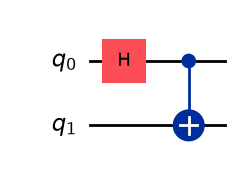

: 

In [ ]:
# A first example of a circuit diagram: H followed by a CNOT.
intro_circuit = QuantumCircuit(2)
intro_circuit.h(0)
intro_circuit.cx(0, 1)
display(intro_circuit.draw("mpl"))

## 1. Introduction to Gates: CNOT Gate

A quantum circuit is a sequence of unitary operations on qubits. A one-qubit state may be a superposition

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle,\qquad |\alpha|^2+|\beta|^2=1.$$

A measurement returns a classical bit. Repeating the same circuit many times (shots) estimates the outcome probabilities; a single shot is only one sample.

### The controlled-NOT (CNOT) gate

A CNOT has a **control** bit $c$ and a **target** bit $t$. It flips the target iff the control is $1$: $|c,t\rangle\mapsto|c,t\oplus c\rangle$. In Qiskit, `qc.cx(control, target)` applies it.

| Input $|ct\rangle$ | Output |
|:---:|:---:|
| $|00\rangle$ | $|00\rangle$ |
| $|01\rangle$ | $|01\rangle$ |
| $|10\rangle$ | $|11\rangle$ |
| $|11\rangle$ | $|10\rangle$ |

For a general two-qubit input (ordered as control, target),

$$|\psi\rangle=\alpha|00\rangle+\beta|01\rangle+\gamma|10\rangle+\delta|11\rangle,$$

linearity gives

$$\operatorname{CNOT}|\psi\rangle=\alpha|00\rangle+\beta|01\rangle+\gamma|11\rangle+\delta|10\rangle.$$

The amplitudes of the $c=0$ terms remain where they are; the two $c=1$ target amplitudes exchange places. This is why a CNOT acting on $H|0\rangle\otimes|0\rangle$ creates an entangled Bell state.

## 2. Why are circuits run many times?

The next helper runs *simulator-only teaching circuits*. It appends final measurements to a copy of the circuit, prints the complete list of bitstrings (`memory`), and then plots their frequency histogram. These measurement instructions are allowed here, but **never** in a hardware submission.


--- always 00 ---


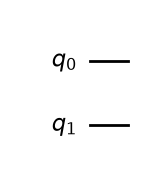

Complete shot list (64 strings):
['00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00']

Counts: {'00': 64}


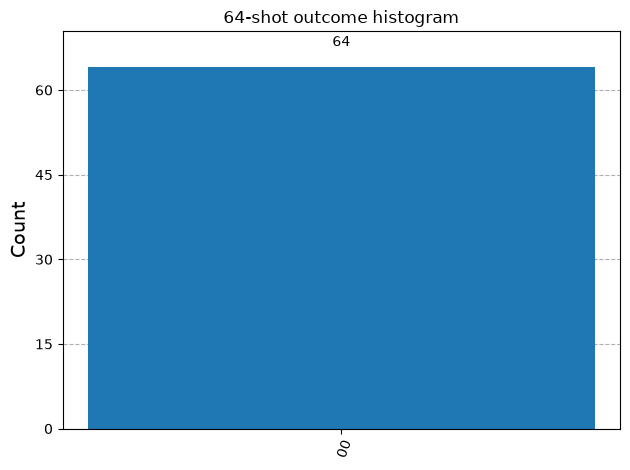


--- X on q0 ---


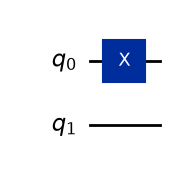

Complete shot list (64 strings):
['01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01', '01']

Counts: {'01': 64}


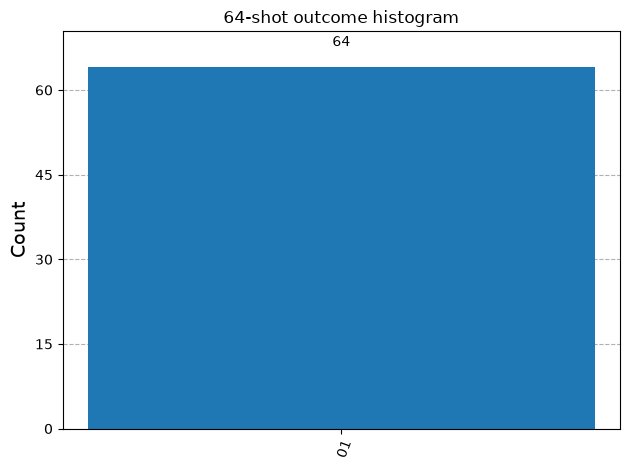


--- Bell-state circuit ---


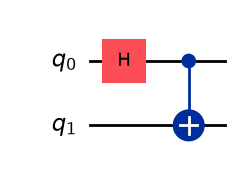

Complete shot list (64 strings):
['11', '00', '00', '11', '00', '11', '11', '11', '11', '00', '11', '00', '11', '00', '00', '00', '11', '00', '11', '00', '00', '00', '11', '11', '00', '00', '00', '11', '11', '11', '11', '00', '11', '00', '00', '11', '00', '11', '00', '11', '00', '00', '11', '00', '00', '11', '00', '00', '11', '11', '00', '00', '00', '11', '11', '11', '11', '00', '11', '00', '11', '00', '00', '11']

Counts: {'00': 33, '11': 31}


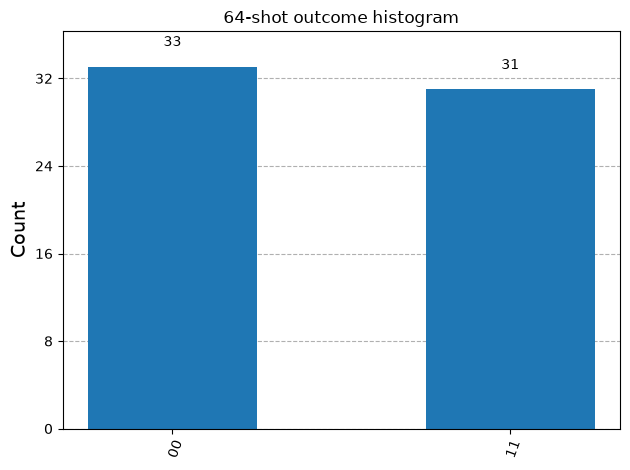

: 

In [ ]:
def run_and_show_memory(circuit, shots=64, seed=7):
    """Run a teaching circuit, print every sampled bitstring, and plot counts."""
    measured = circuit.copy()
    measured.measure_all()
    result = AerSimulator(seed_simulator=seed).run(
        measured, shots=shots, memory=True
    ).result()
    bitstrings = result.get_memory(measured)
    counts = Counter(bitstrings)
    print(f'Complete shot list ({len(bitstrings)} strings):')
    print(bitstrings)
    print('\nCounts:', dict(sorted(counts.items())))
    figure = plot_histogram(counts, title=f'{shots}-shot outcome histogram')
    display(figure)
    plt.close(figure)
    return bitstrings, counts

basic_circuits = {}

basic_circuits['always 00'] = QuantumCircuit(2)

x_on_first = QuantumCircuit(2)
x_on_first.x(0)
basic_circuits['X on q0'] = x_on_first

bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
basic_circuits['Bell-state circuit'] = bell

for name, circuit in basic_circuits.items():
    print(f'\n--- {name} ---')
    display(circuit.draw('mpl'))
    run_and_show_memory(circuit, shots=64)

### Reading the histogram

The height of each bar divided by the number of shots is an empirical probability. For the Bell circuit, ideal quantum mechanics assigns probability $1/2$ to `00` and $1/2$ to `11`; a 64-shot run will generally not return exactly 32 of each. Increasing the number of shots reduces statistical uncertainty, but it cannot undo hardware noise.

Qiskit writes a multi-qubit measurement string with the highest-indexed qubit on the left (`q[n-1] ... q[0]`). The challenge wire convention below deliberately uses this convention so the returned binary integer has the same order as the logical Toffoli bits.

## 3. Problem Statement: Produce the Best Toffoli Gate

The Toffoli, or controlled-controlled-NOT (CCX), has two controls $c_1,c_2$ and a target $t$:

$$|c_1c_2t\rangle\longmapsto |c_1c_2(t\oplus c_1c_2)\rangle.$$

Only when **both** controls equal 1 does the target flip. In some sense, this resembles a 3-qubit, extended version of a CNOT gate.

```text
c₁ ──●──
     │
c₂ ──●──
     │
 t ──⊕──
```

| $c_1c_2t$ input | output |
|:---:|:---:|
| 000 | 000 |
| 001 | 001 |
| 010 | 010 |
| 011 | 011 |
| 100 | 100 |
| 101 | 101 |
| 110 | 111 |
| 111 | 110 |

A high-level Qiskit `ccx` is convenient for describing the desired operation but is **not** an allowed submission instruction. The competition is about replacing it with a short, accurate sequence from the supplied native gates.

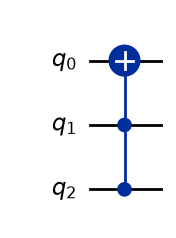

: 

In [ ]:
# The target in the challenge's wire convention: controls q[2], q[1]; target q[0].
toffoli_picture = QuantumCircuit(3, name='Toffoli')
toffoli_picture.ccx(2, 1, 0)
display(toffoli_picture.draw('mpl'))


### Starting points for synthesis

Useful references (read critically—many textbook decompositions assume a different native entangling gate):

- [Qiskit transpilation guide](https://quantum.cloud.ibm.com/docs/en/guides/transpile). Note that `transpile(circuit, basis_gates=["rx", "ry", "rz", "rxx"])` compiles directly to this challenge's native gates; Section 7 uses it to give you a baseline to beat.
- [Qiskit unitary-synthesis documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.transpiler.passes.UnitarySynthesis)
- [Qiskit synthesis overview](https://quantum.cloud.ibm.com/docs/en/guides/synthesize-unitary-operators)
- [OpenQASM 2 export in current Qiskit](https://quantum.cloud.ibm.com/docs/en/guides/interoperate-qiskit-qasm2)
- [BQSKit](https://bqskit.readthedocs.io/en/latest/), a numerical synthesis and optimization toolkit.

Background reading on Toffoli gates and trapped-ion compilation:

- D. Maslov, [Basic circuit compilation techniques for an ion-trap quantum machine](https://arxiv.org/abs/1603.07678) (2017): circuit identities for the `rxx` (Mølmer–Sørensen) gate, including Toffoli constructions.
- V. Shende and I. Markov, [On the CNOT-cost of TOFFOLI gates](https://arxiv.org/abs/0803.2316) (2009): lower bounds on how many two-qubit gates a Toffoli needs.
- T. Monz *et al.*, [Realization of the quantum Toffoli gate with trapped ions](https://arxiv.org/abs/0804.0082) (2009), and C. Figgatt *et al.*, [Complete 3-qubit Grover search on a programmable quantum computer](https://arxiv.org/abs/1703.10535) (2017): Toffoli-type gates on real ion-trap hardware.

Keep the *logical target* fixed while exploring alternatives: cancellation of adjacent rotations, identities up to global phase, different control/target conventions, and re-synthesis of short two-qubit blocks are all fair game.


# ** HARDWARE SHOTS ARE LIMITED — VERIFY ON A SIMULATOR FIRST**

**Each team has a total hardware budget of **20,000 shots** on the DQC trapped-ion quantum computer for the entire challenge.** Every device execution consumes this shared budget: retries, alternate decompositions, calibration experiments, and all circuits in an error-mitigation ensemble count.

**Hardware submissions are accepted only from 4:00 PM to 12:00 midnight.** The relay rejects anything sent outside that window. Your final circuit all have to enter the queue before midnight, so leave yourself time for the lab to return results and for a second attempt. Expect uptime from submission time until results are returned.

**Do not use hardware to debug a circuit.** Before submitting, verify its unitary action, wire order, native-gate compliance, and output format on a simulator.

The menu entry in a submission is one of `64`, `128`, `256`, `512`, or `1024` shots. The lab runs each submission for the specified number of shots, from the initial state `|000>`. Choose your shot number wisely—you have a strict budget!

## 4. Real hardware is noisy

An ideal gate applies exactly its intended unitary. But, real quantum computers are noisy. Errors can happen when running quantum gates. Noise channels provide a mathematical representation of how noise affects our quantum states.

This challenge has three simulator stages:

1. **A known, disclosed noise model.** Its parameters are visible and let you practice diagnosing a structured error.
2. **A mystery backend.** It returns samples but does not disclose its model; use probe circuits to form and test hypotheses.
3. **Your own local models.** Build models that stress-test a candidate before any hardware submission.

None of these simulators is a calibration model of the live device. They are development tools for learning how a correct unitary can still produce imperfect samples.

Ideal counts:               {'00': 1024}
Known-noise counts:         {'01': 10, '10': 12, '11': 150, '00': 852}
Known noise, compensated:   {'01': 9, '10': 10, '00': 1005}


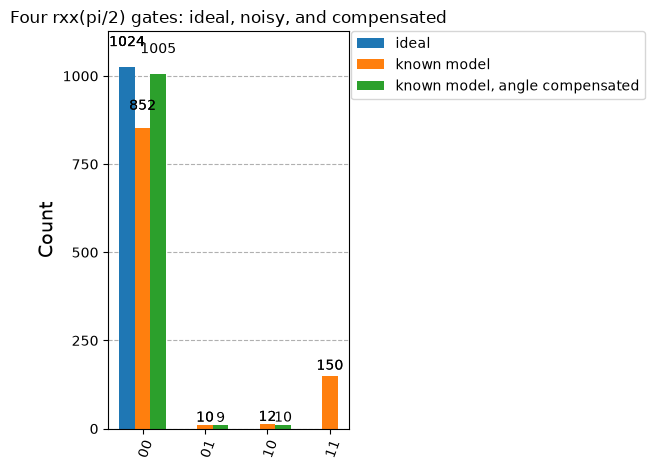

: 

In [ ]:
# 4.1 Known noise model: a compensated RXX overrotation
#
# The model is fully disclosed in toffoli_challenge/known_noise.py:
#   * every rxx(theta) is followed by rxx(+0.2), so its net angle is theta + 0.2;
#   * rx and ry have depolarizing probability 0.001;
#   * readout is asymmetric: 1 -> 0 is more likely than 0 -> 1.
#
# A single small overrotation is hard to see in a histogram. Repeating the gate
# amplifies it: four rxx(pi/2) gates make rxx(2*pi), which is the identity up to a
# global phase, so the ideal output is always 00. Under the known model the four
# offsets add up to 0.8 rad and some shots flip to 11. Since rxx rotations share a
# generator, commanding theta - 0.2 instead of theta cancels the coherent part; the
# remaining stochastic and readout errors cannot be removed by this compensation.
from toffoli_challenge.known_noise import run_with_final_measurements

OVERROTATION = 0.2

def repeated_rxx(angle, repetitions=4):
    circuit = QuantumCircuit(2)
    for _ in range(repetitions):
        circuit.rxx(angle, 0, 1)
    return circuit

ideal_demo = repeated_rxx(np.pi / 2)
ideal_demo.measure_all()
ideal_counts = AerSimulator(seed_simulator=19).run(ideal_demo, shots=1024).result().get_counts()
known_counts = run_with_final_measurements(repeated_rxx(np.pi / 2), shots=1024, seed=19)
compensated_counts = run_with_final_measurements(
    repeated_rxx(np.pi / 2 - OVERROTATION), shots=1024, seed=19
)

print('Ideal counts:              ', ideal_counts)
print('Known-noise counts:        ', known_counts)
print('Known noise, compensated:  ', compensated_counts)
figure = plot_histogram(
    [ideal_counts, known_counts, compensated_counts],
    legend=['ideal', 'known model', 'known model, angle compensated'],
    title='Four rxx(pi/2) gates: ideal, noisy, and compensated',
)
display(figure)
plt.close(figure)


### 4.2 Build and test your own noise models

The disclosed warm-up model is intentionally narrow. Qiskit Aer supports several useful model families:

- **Stochastic gate channels:** depolarizing, Pauli, amplitude damping, phase damping, and thermal-relaxation errors.
- **Coherent errors:** a fixed unwanted unitary such as an RXX overrotation.
- **Readout errors:** a classical assignment matrix applied at measurement.
- **Backend-derived approximations:** a model built from a backend or fake-backend calibration snapshot.

Useful references:

- [Qiskit Aer: building custom noise models](https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html)
- [Qiskit Aer noise-model API](https://qiskit.github.io/qiskit-aer/apidocs/aer_noise.html)
- [Qiskit Aer: device-backend noise-model simulations](https://qiskit.github.io/qiskit-aer/tutorials/2_device_noise_simulation.html)
- [Qiskit Aer: applying noise to custom unitary gates](https://qiskit.github.io/qiskit-aer/tutorials/4_custom_gate_noise.html)

When comparing decompositions, vary both coherent and stochastic assumptions. A circuit that is best under depolarizing noise need not be best under systematic entangling-angle error or asymmetric readout.

In [ ]:
"""Lower-angle reference Toffoli: 5 rxx at +-pi/3 and pi/4 (sum = 19*pi/12), 7 ry, free rz.

Same wire convention and API as reference_toffoli.py: q[2] = c1, q[1] = c2, q[0] = target.
Most angles are clean fractions of pi.  Eight single-qubit angles are not (they are written as
decimal*pi): the circuit is an exact Toffoli only with those specific values, so keep all digits.
One of them is tied to the "magic angle": 0.195913283*pi = atan(1/sqrt(2)).
Checked against the ideal Toffoli with an independent NumPy simulation (fidelity ~ 1 - 1e-15);
check it in your own Qiskit environment before use.
"""
from math import pi
from qiskit import QuantumCircuit

GATES = [
    ("rz", (0,), -0.695913261*pi),
    ("rz", (1,), -3*pi/4),
    ("ry", (1,), pi/2),
    ("rz", (1,), -pi),
    ("rz", (2,), 2*pi/3),
    ("rxx", (0, 1), pi/3),
    ("rz", (0,), 0.804086709*pi),
    ("ry", (0,), -pi/2),
    ("rz", (0,), -0.195913283*pi),
    ("rz", (1,), -5*pi/12),
    ("rz", (2,), pi/6),
    ("ry", (2,), pi/2),
    ("rz", (2,), -pi),
    ("rxx", (0, 2), -pi/3),
    ("rz", (0,), 0.608173462*pi),
    ("rz", (1,), 5*pi/12),
    ("rz", (2,), -5*pi/12),
    ("rxx", (0, 1), pi/3),
    ("rz", (0,), -0.547947298*pi),
    ("ry", (0,), -0.320577980*pi),
    ("rz", (0,), -pi/12),
    ("rz", (1,), -pi/3),
    ("rz", (2,), -7*pi/12),
    ("rxx", (0, 2), -pi/3),
    ("rz", (0,), -pi/12),
    ("rz", (1,), -2*pi/3),
    ("rxx", (1, 2), pi/4),
    ("rz", (0,), -pi),
    ("ry", (0,), -0.679422045*pi),
    ("rz", (0,), 0.852033996*pi),
    ("ry", (1,), -pi/2),
    ("rz", (1,), pi/2),
    ("rz", (2,), -pi),
    ("ry", (2,), pi/2),
    ("rz", (2,), -pi/12),
]


def reference_toffoli(rxx_offset: float = 0.0) -> QuantumCircuit:
    qc = QuantumCircuit(3)
    for name, qubits, angle in GATES:
        if name == "rxx":
            qc.rxx(angle - rxx_offset, *qubits)
        elif name == "ry":
            qc.ry(angle, *qubits)
        else:
            qc.rz(angle, *qubits)
    return qc


# =====================================================================
# ADDED SECTION: accuracy check using the challenge's built-in functions
# Run this file directly (python reference_toffoli_pi3.py) or paste it into a notebook cell.
# It runs on the local simulator only, so it costs no hardware shots.
# =====================================================================
if __name__ == "__main__":
    print("=" * 70)
    print(">>> NEW SECTION ADDED: accuracy check with the built-in challenge functions <<<")
    print("=" * 70)

    import numpy as np
    from toffoli_challenge import compare_to_toffoli, validate_submission_circuit
    from toffoli_challenge.known_noise import known_noise_truth_table

    SHOTS = 4096  # shots per input row on the simulator

    # 1) Ideal (noise-free) correctness: exact unitary comparison with the Toffoli.
    c0 = reference_toffoli()
    validate_submission_circuit(c0)                 # raises ValueError if it breaks the rules
    max_err, proc_fid, avg_fid = compare_to_toffoli(c0)
    print("Gate counts:", dict(c0.count_ops()))
    print(f"Ideal unitary check -> max matrix error {max_err:.2e}, "
          f"process fidelity {proc_fid:.12f}, average gate fidelity {avg_fid:.12f}")

    # 2) Noisy accuracy: eight-input truth-table success rate under the disclosed noise model.
    settings = [
        ("uncompensated (known model, rxx offset 0.2)", 0.0, {}),
        ("compensated by 0.2 (known model)",            0.2, {}),
        ("compensated by 0.2, but TRUE offset is 0.3",  0.2, {"rxx_overrotation": 0.3}),
    ]
    for label, offset, noise in settings:
        c = reference_toffoli(rxx_offset=offset)
        validate_submission_circuit(c)
        report = known_noise_truth_table(c, shots=SHOTS, **noise)
        probs = [r.success_probability for r in report.per_input.values()]
        se = float(np.sqrt(sum(p * (1 - p) / SHOTS for p in probs)) / 8)
        print(f"\n{label}\n  mean truth-table success: {report.mean_success_probability:.4f} +/- {se:.4f}")
        for bits, r in report.per_input.items():
            print(f"    input {bits} -> ideal {r.ideal_output}: {r.success_probability:.4f}")

>>> NEW SECTION ADDED: accuracy check with the built-in challenge functions <<<
Gate counts: {'rz': 23, 'ry': 7, 'rxx': 5}
Ideal unitary check -> max matrix error 4.53e-08, process fidelity 1.000000000000, average gate fidelity 1.000000000000

uncompensated (known model, rxx offset 0.2)
  mean truth-table success: 0.9043 +/- 0.0016
    input 000 -> ideal 000: 0.9556
    input 001 -> ideal 001: 0.9294
    input 010 -> ideal 010: 0.9141
    input 011 -> ideal 011: 0.8892
    input 100 -> ideal 100: 0.9138
    input 101 -> ideal 101: 0.8896
    input 110 -> ideal 111: 0.8594
    input 111 -> ideal 110: 0.8831

compensated by 0.2 (known model)
  mean truth-table success: 0.9197 +/- 0.0015
    input 000 -> ideal 000: 0.9558
    input 001 -> ideal 001: 0.9294
    input 010 -> ideal 010: 0.9329
    input 011 -> ideal 011: 0.9082
    input 100 -> ideal 100: 0.9297
    input 101 -> ideal 101: 0.9055
    input 110 -> ideal 111: 0.8872
    input 111 -> ideal 110: 0.9089

compensated by 0.2, but T

: 

In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from toffoli_challenge import with_input_preparation, compare_to_toffoli, validate_submission_circuit
from toffoli_challenge.benchmarking import TOFFOLI_INPUTS, expected_output_bitstring
from toffoli_challenge.known_noise import run_with_final_measurements
# from reference_toffoli import reference_toffoli   # reference_toffoli.py saved next to this notebook

# ---------------------------------------------------------------- helpers
_I = np.eye(2, dtype=complex)
_P = {"X": np.array([[0, 1], [1, 0]], complex),
      "Y": np.array([[0, -1j], [1j, 0]], complex),
      "Z": np.diag([1, -1]).astype(complex)}
_AXIS = {"rx": _P["X"], "ry": _P["Y"], "rz": _P["Z"]}


def _rot(name, t):
    return np.cos(t / 2) * _I - 1j * np.sin(t / 2) * _AXIS[name]


def _ops(circ):
    """Yield (gate name, params, qubit indices) for every instruction."""
    for inst in circ.data:
        yield inst.operation, [circ.find_bit(q).index for q in inst.qubits]


def _emit_block(out, q, U):
    """Append a 2x2 unitary as rz-ry-rz: at most ONE noisy ry, and none if U is diagonal."""
    U = U / np.sqrt(np.linalg.det(U))              # SU(2); global phase is irrelevant
    c, s = abs(U[0, 0]), abs(U[1, 0])
    if s < 1e-9:                                   # diagonal -> a single free rz
        ang = -2 * np.angle(U[0, 0])
        if abs(np.angle(np.exp(1j * ang))) > 1e-9:
            out.rz(float(ang), q)
        return
    b = 2 * np.arctan2(s, c)
    tot = -2 * np.angle(U[0, 0]) if c > 1e-9 else 0.0   # a + g
    dif = 2 * np.angle(U[1, 0])                          # a - g
    a, g = (tot + dif) / 2, (tot - dif) / 2              # U = rz(a) ry(b) rz(g), rz(g) first
    if abs(g) > 1e-9:
        out.rz(float(g), q)
    out.ry(float(b), q)
    if abs(a) > 1e-9:
        out.rz(float(a), q)


def merge_1q(circ):
    """Fold adjacent single-qubit gates between rxx gates into one rz-ry-rz block per wire."""
    out = QuantumCircuit(3)
    acc = [_I.copy() for _ in range(3)]

    def flush(q):
        _emit_block(out, q, acc[q])
        acc[q] = _I.copy()

    for op, qs in _ops(circ):
        if op.name == "rxx":
            flush(qs[0]); flush(qs[1])
            out.rxx(float(op.params[0]), *qs)
        else:
            acc[qs[0]] = _rot(op.name, float(op.params[0])) @ acc[qs[0]]
    for q in range(3):
        flush(q)
    return out


def _pauli(qc, p, q):                               # Paulis as native gates (global phase irrelevant)
    if p == "X": qc.rx(np.pi, q)
    elif p == "Y": qc.ry(np.pi, q)
    elif p == "Z": qc.rz(np.pi, q)                  # virtual, free


def randomized_compile(circ, rng):
    """Randomized compiling (Wallman & Emerson): random Paulis around every rxx, same logical gate.
    A Pauli pair anticommuting with X(x)X flips the sign of the rxx angle: P rxx(-t) P = rxx(t)."""
    out = QuantumCircuit(3)
    for op, qs in _ops(circ):
        if op.name != "rxx":
            out.append(op, qs); continue
        th = float(op.params[0])
        pa, pb = "IXYZ"[rng.integers(4)], "IXYZ"[rng.integers(4)]
        flip = (pa in "YZ") != (pb in "YZ")         # anticommutes with X(x)X
        _pauli(out, pa, qs[0]); _pauli(out, pb, qs[1])
        out.rxx(-th if flip else th, *qs)
        _pauli(out, pa, qs[0]); _pauli(out, pb, qs[1])
    return out


def apply_offset(circ, off):
    """Pre-compensate a known additive rxx over-rotation: PHYSICAL angle = intended angle - off.
    Apply this AFTER randomized_compile so the correction is the same for flipped gates."""
    out = QuantumCircuit(3)
    for op, qs in _ops(circ):
        if op.name == "rxx":
            out.rxx(float(op.params[0]) - off, *qs)
        else:
            out.append(op, qs)
    return out


# ---------------------------------------------------------------- experiment
def truth_table(variants, offset=0.0, shots=64, seed=0, **noise):
    """Truth table over logically identical circuits. Every (variant, input) pair is one
    submission of `shots` shots; the per-input success pools all variants.
    Returns (per-input success dict, mean, standard error of the mean)."""
    rng = np.random.default_rng(seed)
    per, ses = {}, []
    for x in TOFFOLI_INPUTS:
        ok = 0
        for v in variants:
            c = merge_1q(apply_offset(with_input_preparation(v, x), offset))
            validate_submission_circuit(c)
            counts = run_with_final_measurements(c, shots=shots, seed=int(rng.integers(1_000_000_000)), **noise)
            ok += counts.get(expected_output_bitstring(x), 0)
        n = len(variants) * shots
        p = ok / n
        per[x] = p
        ses.append(np.sqrt(p * (1 - p) / n))
    return per, float(np.mean(list(per.values()))), float(np.sqrt(np.sum(np.square(ses))) / 8)


# ---------------------------------------------------------------- demo (known-noise simulator)
cand = reference_toffoli()                          # exact Toffoli, NOT pre-compensated
rng = np.random.default_rng(1)
R = 8
rc_variants = []
for _ in range(R):
    v = randomized_compile(cand, rng)
    assert compare_to_toffoli(v)[1] > 1 - 1e-9      # every variant is still an exact Toffoli
    rc_variants.append(v)

noise = dict(rxx_overrotation=0.2)                  # swap in other offsets to stress-test
for label, vs, off in [("plain, no compensation", [cand], 0.0),
                       ("plain, compensated 0.2", [cand], 0.2),
                       ("RC, no compensation", rc_variants, 0.0),
                       ("RC + compensated 0.2", rc_variants, 0.2)]:
    shots = 512 // len(vs)                          # same 512 shots per input for every row
    _, mean, se = truth_table(vs, offset=off, shots=shots, seed=7, **noise)
    print(f"{label:26s} {mean:.4f} +/- {se:.4f}   ({8 * shots * len(vs)} shots total)")


plain, no compensation     0.9028 +/- 0.0046   (4096 shots total)
plain, compensated 0.2     0.9177 +/- 0.0043   (4096 shots total)
RC, no compensation        0.8999 +/- 0.0047   (4096 shots total)
RC + compensated 0.2       0.9229 +/- 0.0041   (4096 shots total)


: 

Circuits taken from D. Maslov, New J. Phys. 19, 023035 (2017), arXiv:1603.07678, Figure 3

Maslov 2017, Fig. 3(a): gates {'ry': 6, 'rx': 6, 'rxx': 5}, rxx angles [0.7854, 0.7854, -1.5708, 0.7854, -1.5708]
    ideal max error 5.24e-16, ideal process fidelity 1.000000


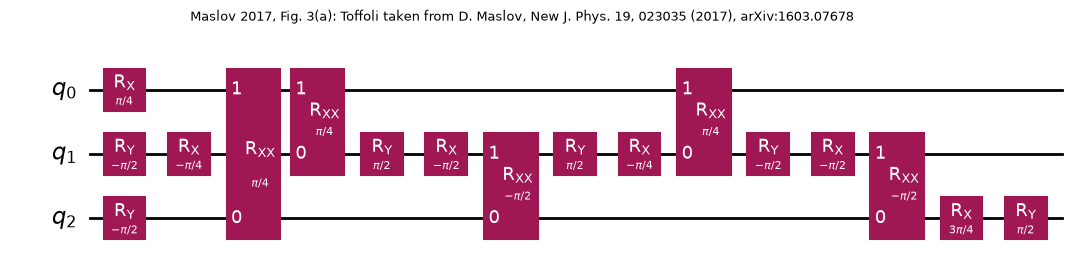

Maslov 2017, Fig. 3(b): gates {'rx': 6, 'rxx': 5, 'ry': 4, 'rz': 4}, rxx angles [0.7854, 0.7854, -1.5708, 0.7854, -1.5708]
    ideal max error 3.38e-16, ideal process fidelity 1.000000


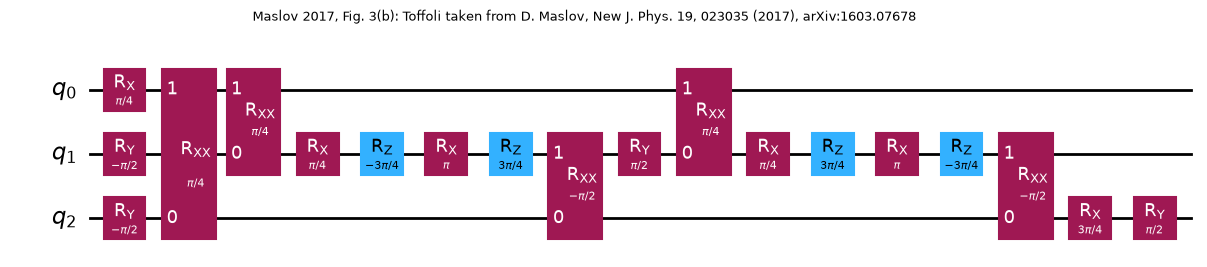

Maslov 2017, Fig. 3(c): gates {'rz': 10, 'rx': 8, 'rxx': 5, 'ry': 1}, rxx angles [0.7854, 0.7854, -1.5708, 0.7854, -1.5708]
    ideal max error 3.74e-16, ideal process fidelity 1.000000


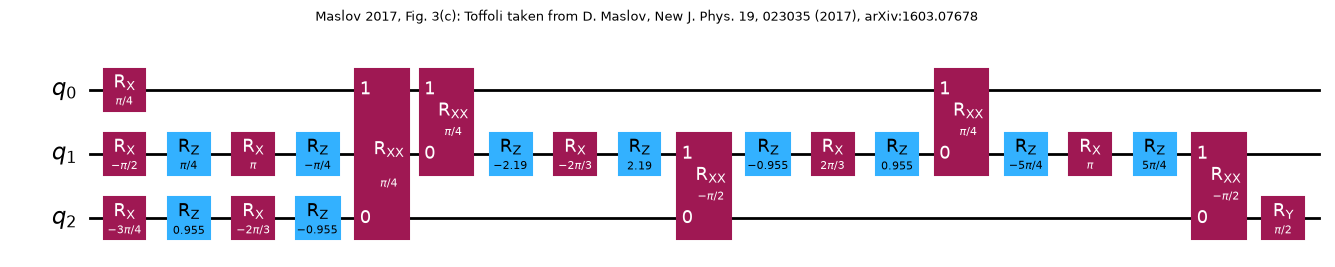

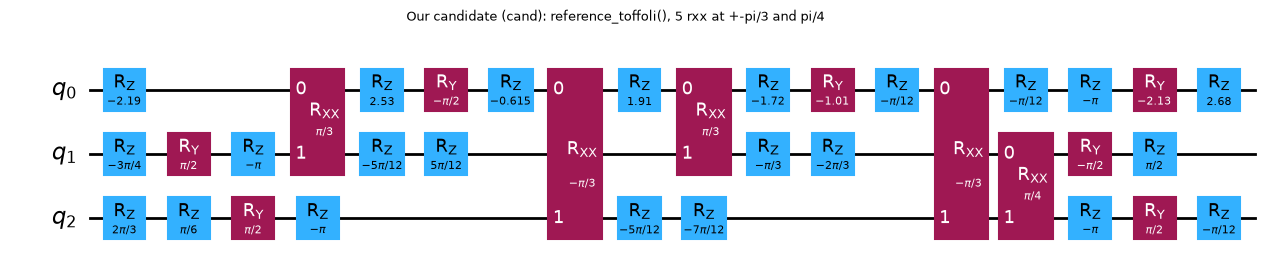


Global phase relative to the ideal Toffoli:
our candidate (cand)     +0.1250*pi rad   (circuit.global_phase = +0.0000*pi)
Maslov 2017, Fig. 3(a)   +0.3750*pi rad   (circuit.global_phase = +0.0000*pi)
Maslov 2017, Fig. 3(b)   +0.3750*pi rad   (circuit.global_phase = +0.0000*pi)
Maslov 2017, Fig. 3(c)   +0.3750*pi rad   (circuit.global_phase = +0.0000*pi)

Known-noise truth table, 512 shots per input:
our candidate (cand)     offset 0.0: 0.9028 +/- 0.0046
our candidate (cand)     offset 0.2: 0.9177 +/- 0.0043
Maslov 2017, Fig. 3(a)   offset 0.0: 0.8682 +/- 0.0052
Maslov 2017, Fig. 3(a)   offset 0.2: 0.9180 +/- 0.0043
Maslov 2017, Fig. 3(b)   offset 0.0: 0.8682 +/- 0.0052
Maslov 2017, Fig. 3(b)   offset 0.2: 0.9180 +/- 0.0043
Maslov 2017, Fig. 3(c)   offset 0.0: 0.8682 +/- 0.0052
Maslov 2017, Fig. 3(c)   offset 0.2: 0.9180 +/- 0.0043

Hardware-ready circuits (unnecessary single-qubit gates removed):
our candidate (cand)     noisy rx/ry  7 ->  7   gates {'rz': 14, 'ry': 7, 'rxx': 5}   ide

: 

In [ ]:
# Maslov's trapped-ion Toffoli circuits, Figure 3(a), 3(b) and 3(c), transcribed into our native gates.
#
# Source: D. Maslov, "Basic circuit compilation techniques for an ion-trap quantum machine",
#         New J. Phys. 19, 023035 (2017), arXiv:1603.07678, Figure 3 (Section 5.1).
#
# All three are Barenco's five-gate Toffoli, CV(c1,t) CV(c2,t) CNOT(c1,c2) CV+(c2,t) CNOT(c1,c2),
# with each two-qubit gate compiled to ONE XX gate (paper eq. 9 and Fig. 1):
#   (a) single-qubit gates aggregated; (b) optimized for time, then error; (c) optimized for error, then time.
#
# Translating the paper's conventions into Qiskit:
#   * paper XX(chi) = exp(-i chi X(x)X)       -> rxx(2*chi), so XX(pi/8) = rxx(pi/4), XX(-pi/4) = rxx(-pi/2)
#   * paper R(theta, phi) = exp(-i theta/2 (cos(phi) X + sin(phi) Y))
#                                             -> rz(-phi), rx(theta), rz(phi)   (rz is free here)
#   * paper ions 2, 4, 5 (controls, controls, target) -> our wires q[2] = c1, q[1] = c2, q[0] = t
#   * the paper's figures read left to right in circuit order, like Qiskit's
MASLOV_2017 = 'D. Maslov, New J. Phys. 19, 023035 (2017), arXiv:1603.07678'
q_c1, q_c2, q_t = 2, 1, 0                           # ions 2, 4, 5 in the paper


def _xx(qc, chi, a, b):                             # paper XX(chi)
    qc.rxx(2 * chi, a, b)


def _r(qc, theta, phi, q):                          # paper R(theta, phi)
    qc.rz(-phi, q); qc.rx(theta, q); qc.rz(phi, q)


def maslov_fig3a():
    """Maslov (2017) Fig. 3(a): Toffoli with single-qubit gates aggregated."""
    qc = QuantumCircuit(3)
    qc.ry(-np.pi / 2, q_c1)
    qc.ry(-np.pi / 2, q_c2); qc.rx(-np.pi / 4, q_c2)
    qc.rx(np.pi / 4, q_t)
    _xx(qc, np.pi / 8, q_c1, q_t)
    _xx(qc, np.pi / 8, q_c2, q_t)
    qc.ry(np.pi / 2, q_c2); qc.rx(-np.pi / 2, q_c2)
    _xx(qc, -np.pi / 4, q_c1, q_c2)
    qc.ry(np.pi / 2, q_c2); qc.rx(-np.pi / 4, q_c2)
    _xx(qc, np.pi / 8, q_c2, q_t)
    qc.ry(-np.pi / 2, q_c2); qc.rx(-np.pi / 2, q_c2)
    _xx(qc, -np.pi / 4, q_c1, q_c2)
    qc.rx(3 * np.pi / 4, q_c1); qc.ry(np.pi / 2, q_c1)
    return qc


def maslov_fig3b():
    """Maslov (2017) Fig. 3(b): Fig. 3(a) optimized for time first, error second."""
    qc = QuantumCircuit(3)
    qc.ry(-np.pi / 2, q_c1)
    qc.ry(-np.pi / 2, q_c2)
    qc.rx(np.pi / 4, q_t)
    _xx(qc, np.pi / 8, q_c1, q_t)
    _xx(qc, np.pi / 8, q_c2, q_t)
    qc.rx(np.pi / 4, q_c2); _r(qc, np.pi, 3 * np.pi / 4, q_c2)
    _xx(qc, -np.pi / 4, q_c1, q_c2)
    qc.ry(np.pi / 2, q_c2)
    _xx(qc, np.pi / 8, q_c2, q_t)
    qc.rx(np.pi / 4, q_c2); _r(qc, np.pi, -3 * np.pi / 4, q_c2)
    _xx(qc, -np.pi / 4, q_c1, q_c2)
    qc.rx(3 * np.pi / 4, q_c1); qc.ry(np.pi / 2, q_c1)
    return qc


def maslov_fig3c():
    """Maslov (2017) Fig. 3(c): Fig. 3(a) optimized for error first, time second."""
    a = np.arcsin(np.sqrt(2 / 3))                   # ~0.304087*pi, as in the paper
    qc = QuantumCircuit(3)
    qc.rx(-3 * np.pi / 4, q_c1); _r(qc, -2 * np.pi / 3, -a, q_c1)
    qc.rx(-np.pi / 2, q_c2); _r(qc, np.pi, -np.pi / 4, q_c2)
    qc.rx(np.pi / 4, q_t)
    _xx(qc, np.pi / 8, q_c1, q_t)
    _xx(qc, np.pi / 8, q_c2, q_t)
    _r(qc, -2 * np.pi / 3, np.pi - a, q_c2)
    _xx(qc, -np.pi / 4, q_c1, q_c2)
    _r(qc, 2 * np.pi / 3, a, q_c2)
    _xx(qc, np.pi / 8, q_c2, q_t)
    _r(qc, np.pi, 5 * np.pi / 4, q_c2)
    _xx(qc, -np.pi / 4, q_c1, q_c2)
    qc.ry(np.pi / 2, q_c1)
    return qc


maslov_circuits = {
    'Maslov 2017, Fig. 3(a)': maslov_fig3a(),
    'Maslov 2017, Fig. 3(b)': maslov_fig3b(),
    'Maslov 2017, Fig. 3(c)': maslov_fig3c(),
}

print(f'Circuits taken from {MASLOV_2017}, Figure 3\n')
for label, circuit in maslov_circuits.items():
    validate_submission_circuit(circuit)
    max_error, process_fidelity, _ = compare_to_toffoli(circuit)
    rxx_angles = [round(float(inst.operation.params[0]), 4) for inst in circuit.data if inst.operation.name == 'rxx']
    print(f'{label}: gates {dict(circuit.count_ops())}, rxx angles {rxx_angles}')
    print(f'    ideal max error {max_error:.2e}, ideal process fidelity {process_fidelity:.6f}')
    figure = circuit.draw('mpl')
    figure.suptitle(f'{label}: Toffoli taken from {MASLOV_2017}', fontsize=9)
    display(figure)
    plt.close(figure)

# Our own candidate, drawn the same way.
figure = cand.draw('mpl')
figure.suptitle('Our candidate (cand): reference_toffoli(), 5 rxx at +-pi/3 and pi/4', fontsize=9)
display(figure)
plt.close(figure)

# Global phase of each circuit relative to the ideal Toffoli: U_circuit = exp(i*phase) * U_Toffoli.
# It has no observable effect (no measurement can see it), so every circuit here is still an exact Toffoli.
# Qiskit's circuit.global_phase is only the phase it tracks as a bookkeeping term inside the circuit.
from qiskit.quantum_info import Operator
from toffoli_challenge import ideal_toffoli_in_submission_order

toffoli_matrix = Operator(ideal_toffoli_in_submission_order()).data
print('\nGlobal phase relative to the ideal Toffoli:')
for label, circuit in [('our candidate (cand)', cand), *maslov_circuits.items()]:
    overlap = np.trace(toffoli_matrix.conj().T @ Operator(circuit).data)
    phase = np.angle(overlap)
    print(f'{label:24s} {phase / np.pi:+.4f}*pi rad   (circuit.global_phase = {circuit.global_phase / np.pi:+.4f}*pi)')

# Same known-noise truth table as our candidate above (512 shots per input), for a direct comparison.
print('\nKnown-noise truth table, 512 shots per input:')
for label, circuit in [('our candidate (cand)', cand), *maslov_circuits.items()]:
    for off in (0.0, 0.2):
        _, mean, se = truth_table([circuit], offset=off, shots=512, seed=7, **noise)
        print(f'{label:24s} offset {off:.1f}: {mean:.4f} +/- {se:.4f}')

# ---------------------------------------------------------------- hardware-ready versions
# Strip every unnecessary single-qubit gate before submitting. Between two rxx gates, each wire's
# rotations are merged into one rz-ry-rz block (at most ONE noisy ry; the rz are free), and gates
# equivalent to the identity are dropped. The rxx gates are left untouched.
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import Optimize1qGatesDecomposition, RemoveIdentityEquivalent

_strip_1q = PassManager([Optimize1qGatesDecomposition(basis=['rz', 'ry']), RemoveIdentityEquivalent()])


def hardware_ready(circuit, input_bits=None, rxx_offset=0.0):
    """Circuit to submit: optional input preparation, optional rxx pre-compensation, then stripped.
    Preparing the input FIRST lets its rx(pi) flips merge into the first block for free.
    Leave rxx_offset at 0 unless you have MEASURED the device's offset (0.2 is the simulator's)."""
    if input_bits is not None:
        circuit = with_input_preparation(circuit, input_bits)
    if rxx_offset:
        circuit = apply_offset(circuit, rxx_offset)
    stripped = _strip_1q.run(circuit)
    validate_submission_circuit(stripped)
    return stripped


def _noisy_pulses(circuit):
    return sum(1 for inst in circuit.data if inst.operation.name in ('rx', 'ry'))


hardware_circuits = {'our candidate (cand)': hardware_ready(cand),
                     **{label: hardware_ready(circuit) for label, circuit in maslov_circuits.items()}}

print('\nHardware-ready circuits (unnecessary single-qubit gates removed):')
for (label, hw), original in zip(hardware_circuits.items(), [cand, *maslov_circuits.values()]):
    _, process_fidelity, _ = compare_to_toffoli(hw)
    print(f'{label:24s} noisy rx/ry {_noisy_pulses(original):2d} -> {_noisy_pulses(hw):2d}   '
          f'gates {dict(hw.count_ops())}   ideal process fidelity {process_fidelity:.6f}')

# Example submissions (hardware window only). Each truth-table row is its own circuit:
# receipt = submit_circuit(hardware_ready(cand, input_bits='110'), shots=64)

## 5. Warm-up on a simulator

Alongside the known model, your team receives access to an **opaque simulator**. It accepts circuits and returns samples, but the noise model is not disclosed. Use a small number of probe circuits to infer its dominant behavior. Is its largest effect consistent with readout error, one-qubit error, entangling-gate error, coherent overrotation, or something else?

This is a simulator-only warm-up and does **not** consume the real-hardware budget. It is designed to reward experimental reasoning, not just compilation. The mystery backend is remote: the hidden model is not present in this repository.

In [ ]:
# The package contains only a remote client; the hidden model is not in this fork.
# Ask the organizers for MYSTERY_BACKEND_URL and, if required, MYSTERY_BACKEND_TOKEN.
import os
from toffoli_challenge.mystery_backend import mystery_backend

# Example event configuration. Do not commit event credentials to your fork.
# os.environ['MYSTERY_BACKEND_URL'] = 'https://organizer.example/mystery'
# os.environ['MYSTERY_BACKEND_TOKEN'] = 'provided-by-organizers'

def mystery_counts(circuit, shots=256):
    # The remote service adds final measurements itself; candidates stay measurement-free.
    return mystery_backend.run(circuit, shots=shots).result().get_counts()


# Suggested native-gate probes. Add your own, but write down the hypothesis each tests.
probes = {}
probes['prepare |0>'] = QuantumCircuit(1)

one_state = QuantumCircuit(1)
one_state.rx(np.pi, 0)
probes['prepare |1> with RX(pi)'] = one_state

two_rx = QuantumCircuit(1)
two_rx.rx(np.pi, 0)
two_rx.rx(np.pi, 0)
probes['two RX(pi) gates (ideal identity)'] = two_rx

entangling_probe = QuantumCircuit(2)
entangling_probe.ry(np.pi / 2, 0)
entangling_probe.rxx(np.pi / 2, 0, 1)
probes['native RXX entangling probe'] = entangling_probe

if not mystery_backend.url:
    print('MYSTERY_BACKEND_URL is not set yet; skipping the probes. Set it above when the organizers share it.')
else:
    for name, probe in probes.items():
        print(f'\n--- {name} ---')
        print(mystery_counts(probe, shots=256))

MYSTERY_BACKEND_URL is not set yet; skipping the probes. Set it above when the organizers share it.


: 

## 6. Challenge specification

**Native gates.** Every quantum computer has a few operations it performs directly; everything else is built from them. On this trapped-ion machine the entangling gate is $R_{XX}(\theta)$, an $XX$ rotation. Your circuit may use only [`rx`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RXGate), [`ry`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RYGate), [`rz`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RZGate) and [`rxx`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RXXGate). `rz` is done in software, so it is free: use it as much as you like.

**Rules for a submitted circuit** (`validate_submission_circuit` checks them all):

- exactly **three** qubits and no classical bits;
- only `rx`, `ry`, `rz`, `rxx`, with plain numerical angles; no measurements, resets, barriers or other instructions (the lab adds the measurements);
- wires: `q[2] = c₁`, `q[1] = c₂`, `q[0] = t`. The target is `ccx(2, 1, 0)`, and every bitstring reads `c₁c₂t`.

**What the lab does with it.** You pick `N` from `64`, `128`, `256`, `512`, `1024`. The lab starts from `|000>`, runs your circuit exactly as written, measures `N` times, and returns one raw list of bitstrings, for example `['111', '111', '110', ...]`, and nothing else. Files are named `<queueID>_<N>_<teamID>.qasm` (yours) and `.txt` (the result). The lab adds no input preparation. To test input `110`, submit `with_input_preparation(candidate, '110')`, and write down which queue ID prepared which input.

The next cell demonstrates the helpers that check circuits and turn raw lists into numbers (code in `toffoli_challenge/`).


3) Validate my circuit:
Native gate counts: {'rx': 8, 'ry': 6, 'rz': 6, 'rxx': 5}
Ideal max error: 1.93e-15; ideal process fidelity: 1.000000

4) Truth table under the known noise model (one raw list per prepared input):
Truth-table success rate: 88.4644%
  000 -> 000: 92.1875%
  001 -> 001: 90.0391%
  010 -> 010: 93.1641%
  011 -> 011: 90.2344%
  100 -> 100: 90.4297%
  101 -> 101: 87.8906%
  110 -> 111: 80.9570%
  111 -> 110: 82.8125%


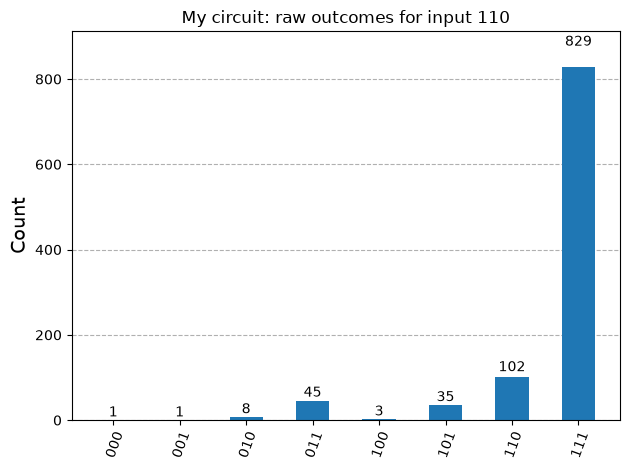

Counts for input 110: {'111': 829, '110': 102, '011': 45, '101': 35, '010': 8, '100': 3, '001': 1, '000': 1}


: 

In [ ]:
import matplotlib.pyplot as plt
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

from toffoli_challenge import (
    TOFFOLI_INPUTS,
    baseline_native_toffoli,
    bitstrings_to_counts,
    compare_to_toffoli,
    truth_table_from_bitstrings,
    validate_submission_circuit,
    with_input_preparation,
)
from toffoli_challenge.known_noise import known_noise_model

my_circuit = baseline_native_toffoli()  # <-- replace with YOUR measurement-free native circuit

print('\n3) Validate my circuit:')
validate_submission_circuit(my_circuit)  # raises ValueError if any gate is not native
print('Native gate counts:', dict(my_circuit.count_ops()))
max_error, process_fidelity, _ = compare_to_toffoli(my_circuit)
print(f'Ideal max error: {max_error:.2e}; ideal process fidelity: {process_fidelity:.6f}')

print('\n4) Truth table under the known noise model (one raw list per prepared input):')
noisy_backend = AerSimulator(noise_model=known_noise_model(), seed_simulator=7)
my_raw_bitstrings = {}
for input_bits in TOFFOLI_INPUTS:
    prepared = with_input_preparation(my_circuit, input_bits)
    prepared.measure_all()
    result = noisy_backend.run(prepared, shots=1024, memory=True).result()
    my_raw_bitstrings[input_bits] = result.get_memory(prepared)

my_report = truth_table_from_bitstrings(my_raw_bitstrings)
print(f'Truth-table success rate: {my_report.mean_success_probability:.4%}')
for input_bits, entry in my_report.per_input.items():
    print(f'  {input_bits} -> {entry.ideal_output}: {entry.success_probability:.4%}')

figure = plot_histogram(my_report.per_input['110'].counts, title='My circuit: raw outcomes for input 110')
display(figure)
plt.close(figure)
print('Counts for input 110:', bitstrings_to_counts(my_raw_bitstrings['110']))


## 7. Develop and verify your candidate locally

Local unitary comparison is a fast way to catch a wrong wire order or a decomposition that differs from Toffoli by more than global phase. It is exact-math verification—not a prediction of device performance.

The next function expects the required convention: candidate `q[2]` and `q[1]` are controls, and `q[0]` is the target. A global phase is accepted because it has no observable effect.

In [ ]:
from toffoli_challenge import compare_to_toffoli, ideal_toffoli_in_submission_order

# This reference circuit is intentionally NOT submission-valid because ccx is high level.
reference_target = ideal_toffoli_in_submission_order()
max_error, process_fidelity, average_gate_fidelity = compare_to_toffoli(reference_target)
print(f'Maximum entrywise error after global-phase alignment: {max_error:.3e}')
print(f'Ideal process fidelity: {process_fidelity:.12f}')
print(f'Ideal average gate fidelity: {average_gate_fidelity:.12f}')
try:
    validate_submission_circuit(reference_target)
except ValueError as error:
    print('As intended, the high-level reference circuit is rejected:')
    print(error)

: 

### A baseline to beat

Qiskit can compile the reference Toffoli straight into the native gate set. The result is a valid, exact submission with five `rxx` gates. Use it as a correctness reference and as the design to beat: the cell below also estimates its truth-table success rate under the known noise model, using the eight-input truth-table experiment explained at the start of Section 8.


In [ ]:
from toffoli_challenge import baseline_native_toffoli
from toffoli_challenge.known_noise import known_noise_truth_table

baseline = baseline_native_toffoli()
validate_submission_circuit(baseline)
print('Native gate counts:', dict(baseline.count_ops()))
max_error, process_fidelity, _ = compare_to_toffoli(baseline)
print(f'Ideal max error: {max_error:.2e}; ideal process fidelity: {process_fidelity:.6f}')
display(baseline.draw('mpl'))

baseline_report = known_noise_truth_table(baseline, shots=1024, seed=7)
print(f'Known-noise truth-table success rate: {baseline_report.mean_success_probability:.4f}')
for input_bits, entry in baseline_report.per_input.items():
    print(f'  {input_bits} -> {entry.ideal_output}: {entry.success_probability:.4f}')


: 

### Strategies worth investigating

There is no single complete mitigation recipe. First distinguish **physical error suppression**—making the circuit itself better—from **estimator mitigation**—post-processing many noisy circuit outcomes into a better estimate. Only the first category improves the raw truth table of a single circuit.

**1. Synthesis, compilation, and coherent-error-aware design**

- Minimize the number and total exposure of entangling `rxx` gates; test distinct exact decompositions, not only gate count.
- Use exact identities and numerical optimization to compress surrounding one-qubit rotations. `rz` is virtual/free, so phase-frame changes are effectively free resources.
- In the disclosed model, each `rxx(θ)` carries a repeatable `+0.2` angle offset. A calibrated angle compensation or a composite/echo-style construction can directly address that coherent component. It will **not** remove the model's depolarization or readout assignment error.
- If the physical model has drift, crosstalk, leakage, or non-Markovian effects, a compensation optimized for a static overrotation can fail. Probe before committing your scarce final shots.

**2. Noise tailoring and suppression**

- Randomized compiling / Pauli twirling can turn coherent buildup into more stochastic-looking noise when an ensemble of logically equivalent circuits is permitted. See [Wallman & Emerson (2016)](https://arxiv.org/abs/1512.01098).
- Dynamical decoupling/echo methods can help idle-time or certain correlated errors, but add gates and are not a generic cure for an entangling-angle error.

**3. Estimator-level error mitigation**

- Readout mitigation estimates and inverts a measured assignment matrix. It can correct *reported probability estimates*, but cannot alter the raw bitstrings already produced.
- Zero-noise extrapolation (ZNE) executes deliberately noise-amplified/folded circuits and extrapolates an **expectation value** toward zero noise. It costs an ensemble of circuits and is not guaranteed to be unbiased. See [Qiskit's mitigation guide](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques).
- Probabilistic error cancellation can in principle mitigate calibrated gate noise, but often has severe sampling overhead—usually unattractive under a small shot budget.

**What this means for your case:** a raw $S_{\mathrm{TT}}$ from one circuit measures *the circuit*. A mitigated number measures *the circuit plus your estimator*. Both are fair evidence in this open challenge, but they answer different questions. If you use mitigation, show the raw numbers next to the mitigated ones, say how many extra shots the mitigation cost, and explain what could make the estimator wrong.

Useful broad references: [Endo *et al.* review](https://arxiv.org/abs/2011.01382), [Cai *et al.* review](https://arxiv.org/abs/2210.00921), and [Qiskit's overview](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-overview).

## 8. Is it really a Toffoli? From truth tables to tomography

### The natural first test: a truth table

There are $2^3 = 8$ computational-basis inputs, `000` to `111`. A truth-table experiment prepares each one, applies your circuit, measures in the $Z$ basis, and checks whether the output is Toffoli's $T(x)$. That is eight input preparations and eight $Z$-basis measurements (not eight different measurement bases). With `N` shots per input, the truth-table success rate is

$$S_{\mathrm{TT}}=\frac18\sum_{x\in\{0,1\}^3}\frac{\#\{\text{shots with }y=T(x)\}}{N},$$

and it costs $8N$ shots: eight submissions, one per input. Experimental papers routinely report one (for example the iToffoli experiment in [Wei *et al.*, *Nature Physics* 18, 597 (2022)](https://www.nature.com/articles/s41567-022-01590-3)).

### Why it is not enough

A truth table asks one question per input: *starting from $|x\rangle$, how often do I measure $T(x)$?* It measures the eight numbers $|\langle T(x)|U|x\rangle|^2$ and never looks at the **phases** of $U$.

That blind spot is large. Any circuit of the form

$$U = \mathrm{Toffoli}\cdot D,\qquad D=\mathrm{diag}(e^{i\phi_{000}},\dots,e^{i\phi_{111}}),$$

passes every truth-table row perfectly, whatever the eight phases $\phi_x$ are. Only a common (global) phase is physically meaningless. *Relative* phases change what the gate does to superpositions, and a Toffoli inside a larger algorithm (Grover search, arithmetic) depends on them. To see them you must probe superposition inputs and measure in other bases. That is what **state and process tomography**, and their cheaper relatives, do. The rest of this section sets up that problem.

The next cell builds an impostor. It uses only **three** `rxx` gates (the baseline uses five), passes 100% of the ideal truth table, and is still not a Toffoli.

In [ ]:
# A relative-phase "lookalike": perfect truth table, wrong gate.
from qiskit import transpile
from qiskit.quantum_info import Statevector
from toffoli_challenge import TOFFOLI_INPUTS, compare_to_toffoli, with_input_preparation

lookalike = QuantumCircuit(3)
lookalike.ry(np.pi / 4, 0)
lookalike.cx(1, 0)
lookalike.ry(np.pi / 4, 0)
lookalike.cx(2, 0)
lookalike.ry(-np.pi / 4, 0)
lookalike.cx(1, 0)
lookalike.ry(-np.pi / 4, 0)
lookalike = transpile(lookalike, basis_gates=['rx', 'ry', 'rz', 'rxx'], optimization_level=3, seed_transpiler=1)
validate_submission_circuit(lookalike)
print('Native gate counts:', dict(lookalike.count_ops()))

print('\nIdeal (noise-free) truth table:')
for input_bits in TOFFOLI_INPUTS:
    probabilities = Statevector(with_input_preparation(lookalike, input_bits)).probabilities_dict()
    output = max(probabilities, key=probabilities.get)
    print(f'  {input_bits} -> {output}   probability {probabilities[output]:.3f}')

_, lookalike_process_fidelity, _ = compare_to_toffoli(lookalike)
print(f'\nIdeal process fidelity with Toffoli: {lookalike_process_fidelity:.4f}  (a true Toffoli gives 1.0000)')


: 

### Your task: design a verification experiment

`compare_to_toffoli` catches the lookalike instantly, but only because it reads the *ideal* unitary of the circuit you wrote. On hardware you cannot read a unitary; you only get bitstrings. So the question is:

> **Using only what the lab offers, design an experiment that would convince a skeptic that your hardware circuit acts as a Toffoli, phases included, and estimate how close it is.**

**The rules you have to work within**

- The lab starts every run in $|000\rangle$ and measures all three qubits in the $Z$ basis. Nothing else.
- So every input state you want and every measurement basis you want must be built from native gates **inside your submitted circuit**: *prepare → your candidate → basis change → (lab measures Z)*.
- Each distinct circuit is a separate submission of `N` shots, charged against your team's budget, and has to enter the queue between **4:00 PM and midnight**.
- An estimated probability from `N` shots carries a statistical error of about $\sqrt{p(1-p)/N}$.

**Building blocks** (check each one with `Statevector` yourself; signs and conventions are easy to get wrong):

| from $|0\rangle$, prepare | native gate | | to measure in basis | apply before the lab's Z measurement |
|:---:|:---:|---|:---:|:---:|
| $|1\rangle$ | `rx(π)` | | $Z$ | nothing |
| $|+\rangle$ | `ry(π/2)` | | $X$ | `ry(-π/2)` |
| $|-\rangle$ | `ry(-π/2)` | | $Y$ | `rx(π/2)` |
| $|{+i}\rangle$ | `rx(-π/2)` | | | |
| $|{-i}\rangle$ | `rx(π/2)` | | | |

**Questions to work through before 4:00 PM**

1. Describe exactly which circuits pass the truth table perfectly. How much extra information do you need to pin $U$ down up to a global phase?
2. Full **process tomography** of a three-qubit operation needs an informationally complete set of input states and of measurement bases. How many distinct circuits is that (for example $4^3$ inputs × $3^3$ bases)? At 64 shots each, how many shots? Compare that with your 20,000-shot budget and with the 8-hour window.
3. Can you find inputs for which the ideal Toffoli output is still easy to recognize, so that one measurement setting gives a clear pass/fail per shot, just like a truth-table row? Which phases $\phi_x$ does each such test actually constrain? Which tests catch the lookalike above?
4. Is there a cheap pair of *classical* fidelities that together bound the process fidelity? (See Hofmann below.)
5. Your preparation and basis-change gates are noisy and readout is imperfect too. How would you tell a bad Toffoli apart from bad state preparation and measurement (SPAM)?
6. Rehearse your whole plan on the simulators (the disclosed known-noise model and the mystery backend) *before* you spend hardware shots. Does it reject the lookalike? Does it give a believable fidelity for the baseline?

The cell after the resources shows how to assemble and rehearse a single verification circuit. Choosing *which* circuits to run, and how to turn their counts into a conclusion, is up to you.

### Resources

**Tomography**

- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, Section 8.4 (quantum process tomography): the standard introduction.
- [Qiskit Experiments: state tomography](https://qiskit-community.github.io/qiskit-experiments/manuals/verification/state_tomography.html) and the [`ProcessTomography` API](https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.library.tomography.ProcessTomography.html). Useful for generating settings and fitting a reconstruction. It is not installed by default (`pip install qiskit-experiments`; check it supports your Qiskit version), and its circuits use non-native preparation/measurement gates and contain measurements, so you must rewrite them in native gates without measurements before submitting.
- J. A. Smolin, J. M. Gambetta and G. Smith, [Efficient method for computing the maximum-likelihood quantum state from measurements with additive Gaussian noise](https://arxiv.org/abs/1106.5458) (2012): turning noisy counts into a physical state.
- [Qiskit `quantum_info`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/quantum_info): `Statevector`, `DensityMatrix`, `Operator`, `Choi`, `process_fidelity` and `state_fidelity` for checking your analysis on simulated data.
- T. Monz *et al.*, [Realization of the quantum Toffoli gate with trapped ions](https://arxiv.org/abs/0804.0082) (2009): a trapped-ion Toffoli characterized by full process tomography. See how they report it.

**Cheaper than full tomography**

- H. F. Hofmann, [Complementary classical fidelities as an efficient criterion for the evaluation of experimentally realized quantum operations](https://arxiv.org/abs/quant-ph/0411011) (*PRL* 94, 160504, 2005): two truth-table-like measurements in complementary bases bound the process fidelity.
- S. T. Flammia and Y.-K. Liu, [Direct fidelity estimation from few Pauli measurements](https://arxiv.org/abs/1104.4695) (2011), and M. P. da Silva, O. Landon-Cardinal and D. Poulin, [Practical characterization of quantum devices without tomography](https://arxiv.org/abs/1104.3835) (2011): estimate fidelity to a target by sampling a few Pauli settings.

**Separating gate errors from SPAM**

- E. Magesan, J. M. Gambetta and J. Emerson, [Robust randomized benchmarking of quantum processes](https://arxiv.org/abs/1009.3639) (2011), and E. Magesan *et al.*, [Efficient measurement of quantum gate error by interleaved randomized benchmarking](https://arxiv.org/abs/1203.4550) (2012).
- A. Erhard *et al.*, [Characterizing large-scale quantum computers via cycle benchmarking](https://arxiv.org/abs/1902.08543) (2019): developed on trapped ions.
- Gate set tomography, which characterizes preparation, gates and measurement together: D. Greenbaum, [Introduction to quantum gate set tomography](https://arxiv.org/abs/1509.02921) (2015).

Randomized benchmarking of a full three-qubit gate is expensive. Think about what it would and would not tell you here before spending shots on it.

In [ ]:
# Assembling and rehearsing ONE verification circuit: prepare -> candidate -> basis change.
# This example (target prepared in |+>, measured in X) is deliberately weak: it does NOT
# catch the lookalike. Designing a set of settings that does is your job.
from toffoli_challenge.known_noise import run_with_final_measurements


def verification_circuit(candidate, prepare, basis_change):
    # All three parts are native and measurement-free; the lab adds the Z measurement.
    circuit = QuantumCircuit(3)
    circuit.compose(prepare, inplace=True)
    circuit.compose(candidate, inplace=True)
    circuit.compose(basis_change, inplace=True)
    validate_submission_circuit(circuit)
    return circuit


prepare = QuantumCircuit(3)
prepare.ry(np.pi / 2, 0)        # target t = q[0] in |+>, controls in |00>
basis_change = QuantumCircuit(3)
basis_change.ry(-np.pi / 2, 0)  # measure the target in the X basis

for name, candidate in [('baseline', baseline), ('lookalike', lookalike)]:
    test = verification_circuit(candidate, prepare, basis_change)
    ideal = Statevector(test).probabilities_dict()
    noisy = run_with_final_measurements(test, shots=1024, seed=11)
    print(f'{name:9s} ideal P(000) = {ideal.get("000", 0):.3f}   known-noise counts: {dict(sorted(noisy.items()))}')

# Submitting it later is the same as any other circuit (between 4 PM and midnight):
# receipt = submit_circuit(verification_circuit(candidate_circuit, prepare, basis_change), shots=64)


: 

## 9. Submit and retrieve results

Submission infrastructure is intentionally under the hood. You do **not** need a GitLab account, GitLab token, SSH key, command-line Git, or repository URL. The organizer-operated relay receives your measurement-free circuit, assigns a queue ID, checks your remaining hardware-shot budget, and handles the private GitLab workflow.

You only call the black-box functions below:

```python
submit_circuit(candidate_circuit, shots=512)
remaining_hardware_shots()
fetch_my_results()
```

Each submission is run once, exactly as written, starting from `|000>`, and returns one result file.

**The queue is open from 4:00 PM to 12:00 midnight only.** Before 4:00 PM and after midnight `submit_circuit(...)` raises an error from the relay and nothing is charged. `remaining_hardware_shots()` and `fetch_my_results()` work at any time, so you can collect results after the queue closes. After midnight the challenge continues on IonQ's cloud until noon (see *What happens at midnight* below).

The organizer provides your team-specific `TEAM_ID` and `TEAM_SECRET`. Do not commit either value to your fork.

### One-time team configuration

Enter the team-specific values supplied by the organizer. The relay address is built into the `toffoli_challenge` package, so there is nothing else to configure. They authenticate your team to the relay; they are **not** GitLab credentials. Keep `TEAM_SECRET` out of commits, screenshots, and public chat.

In [ ]:
# One-time configuration: TEAM_ID and TEAM_SECRET are supplied privately by the organizer.
from getpass import getpass
from toffoli_challenge import (
    connect_team,
    remaining_hardware_shots,
    submit_circuit,
    submit_qasm_text,
)

TEAM_ID = 'TEAM_1'

if TEAM_ID.startswith('PASTE_'):
    print('Fill in TEAM_ID above (from the organizers), then rerun this cell.')
else:
    TEAM_SECRET = getpass('Paste the team relay secret: ')
    connect_team(TEAM_ID, TEAM_SECRET)

    # Check the current team budget at any time.
    status = remaining_hardware_shots()
    print(f"Charged: {status['charged_hardware_shots']}; remaining: {status['hardware_shots_remaining']}")
    # Hardware submissions are accepted only between 4:00 PM and midnight.
    window = status.get('submission_window', {})
    print('Hardware queue is', 'OPEN' if window.get('open') else 'CLOSED',
          f"(opens {window.get('opens_at')}, closes {window.get('closes_at')})")

# Submit directly from a simulator-verified measurement-free QuantumCircuit:
# receipt = submit_circuit(candidate_circuit, shots=512)
# print(receipt['submission'])          # note receipt['submission']['queue_id']


: 

In [ ]:
from getpass import getpass
from toffoli_challenge import (
    connect_team,
    remaining_hardware_shots,
    submit_circuit,
    fetch_my_results,
    results_by_queue_id,
    validate_submission_circuit
)

team_id = "team_1"
secret_word = "6ssR04mxWg1iZXiW0MKVnbuCz3RE3d8PMEXNgWyALoA"

# Connect to the quantum computer
connect_team(team_id, secret_word)

# Check hardware availability and shot budget
status = remaining_hardware_shots()

print("Remaining shots:", status["hardware_shots_remaining"])
print("Queue status:", status.get("submission_window"))

Remaining shots: 20000
Queue status: {'opens_at': '2026-10-24T16:00:00-04:00', 'closes_at': '2026-10-24T23:59:00-04:00', 'open': True}


: 

In [ ]:
# Retrieve only this team's returned raw bitstring-list files.
from toffoli_challenge import (
    TOFFOLI_INPUTS,
    fetch_my_results,
    results_by_queue_id,
    truth_table_from_results,
    with_input_preparation,
)

# Each submission returns one file, <queueID>_<shots>_<teamID>.txt.
# A truth table is eight submissions, one per prepared input. Keep the queue IDs:
# queue_id_by_input = {}
# for input_bits in TOFFOLI_INPUTS:
#     receipt = submit_circuit(with_input_preparation(candidate_circuit, input_bits), shots=64)
#     queue_id_by_input[input_bits] = receipt['submission']['queue_id']
#
# After the lab has run all eight:
# returned = fetch_my_results(destination='returned_results')
# report = truth_table_from_results(returned, queue_id_by_input)
# print(f'Truth-table success rate: {report.mean_success_probability:.4%}')
# for input_bits, entry in report.per_input.items():
#     print(input_bits, '->', entry.ideal_output, f'{entry.success_probability:.4%}')
#
# One submission's raw shots, or everything returned so far:
# print(results_by_queue_id(fetch_my_results(destination=None, queue_id=17)))
# print(list(results_by_queue_id(fetch_my_results(destination=None))))

: 

## What happens at midnight, and what to hand in

**Until midnight:** every lab hardware run must be *in the queue* before 12:00 midnight. Results keep arriving after that, and `fetch_my_results()` works at any time.

**At midnight:**

- the lab queue closes;
- the organizers release the **IonQ extension notebook**, together with instructions for getting it into your repository;
- your team's IonQ project gets its budget.

From then until **noon** you can keep improving and testing your Toffoli on IonQ's **Forte 1** trapped-ion computer, with your own IonQ API key. To be ready:

- accept the IonQ invitation email during the evening;
- check that you can sign in at [cloud.ionq.com](https://cloud.ionq.com) and see your team's project `intro-<your team ID>`;
- the extension notebook walks you through the rest (API key, free simulator, then the QPU).

**Your project submission** (the organizers will announce the deadline):

1. **Your circuit:** the OpenQASM of the Toffoli you claim is best, from `qasm2.dumps(candidate_circuit)`.
2. **Your evidence:** the lab queue IDs and IonQ job IDs behind every hardware number you present.
3. **Your presentation:** about 5 minutes plus about 3 minutes of questions, answering the final challenge below.

## 10. The final challenge: prove that your Toffoli gate is the best

This is the question your team answers at the end, and it is deliberately open. Nobody will plug your numbers into a formula. You present a case, and the judges decide how convincing it is.

**"Best" is yours to define, but you have to defend the definition.** Some questions worth answering explicitly:

- **Best compared to what?** The 5-`rxx` baseline, the other designs you tried, the textbook constructions in Section 3's references. A claim of "best" without a comparison is not a claim.
- **Best by which measure?** Truth-table success rate, phase-sensitive tests, an estimated process fidelity, robustness to the noise you found in Section 5, gate count. Section 8 shows why a perfect truth table alone does not prove you built a Toffoli.
- **How sure are you?** Every probability estimated from `N` shots has a statistical error of about $\sqrt{p(1-p)/N}$. Two designs that differ by less than their error bars are tied until you show otherwise. Hardware also drifts, so a comparison is fairest when the runs are taken close together.
- **On which machine?** The known-noise model, the mystery backend, the lab hardware and (after midnight) IonQ's cloud can disagree. Explain what you think each one told you.
- **What would change your mind?** Name the experiment that could have shown your design is *not* the best, and say whether you ran it.

**What the judges look for**

- **Understanding.** You can explain why your circuit works, why each experiment was worth its shots, and what the data does *not* show. Expect questions, and expect "why?" more than once.
- **Evidence over polish.** Plots of your own data with error bars beat beautiful slides. Every hardware number you present should trace back to a queue ID, so judges can recompute it from the lab's raw files.
- **Honest learning.** Failed ideas, wrong hypotheses and what you changed afterwards count in your favour. A team that understands a modest result beats a team that cannot explain an impressive one.
- **Clear communication.** A short, well-organized story: the question, what you tried, what you measured, what you conclude.

AI assistants are allowed as tools, but the judges are evaluating *your* understanding. If you can't explain a step without the assistant, leave it out.


In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from toffoli_challenge import (
    validate_submission_circuit,
    compare_to_toffoli,
    remaining_hardware_shots
)

pi = np.pi

# ============================================================
# 1. Define optimized Toffoli gates
# ============================================================

GATES = [
    ("rz", (0,), -0.695913261*pi),
    ("rz", (1,), -3*pi/4),
    ("ry", (1,), pi/2),
    ("rz", (1,), -pi),
    ("rz", (2,), 2*pi/3),
    ("rxx", (0, 1), pi/3),
    ("rz", (0,), 0.804086709*pi),
    ("ry", (0,), -pi/2),
    ("rz", (0,), -0.195913283*pi),
    ("rz", (1,), -5*pi/12),
    ("rz", (2,), pi/6),
    ("ry", (2,), pi/2),
    ("rz", (2,), -pi),
    ("rxx", (0, 2), -pi/3),
    ("rz", (0,), 0.608173462*pi),
    ("rz", (1,), 5*pi/12),
    ("rz", (2,), -5*pi/12),
    ("rxx", (0, 1), pi/3),
    ("rz", (0,), -0.547947298*pi),
    ("ry", (0,), -0.320577980*pi),
    ("rz", (0,), -pi/12),
    ("rz", (1,), -pi/3),
    ("rz", (2,), -7*pi/12),
    ("rxx", (0, 2), -pi/3),
    ("rz", (0,), -pi/12),
    ("rz", (1,), -2*pi/3),
    ("rxx", (1, 2), pi/4),
    ("rz", (0,), -pi),
    ("ry", (0,), -0.679422045*pi),
    ("rz", (0,), 0.852033996*pi),
    ("ry", (1,), -pi/2),
    ("rz", (1,), pi/2),
    ("rz", (2,), -pi),
    ("ry", (2,), pi/2),
    ("rz", (2,), -pi/12),
]

# ============================================================
# 2. Build optimized Toffoli circuit
# ============================================================

def build_model(gates):
    qc = QuantumCircuit(3)

    for name, qubits, angle in gates:
        if name == "rxx":
            qc.rxx(angle, *qubits)
        elif name in ("rx", "ry", "rz"):
            getattr(qc, name)(angle, qubits[0])
        else:
            raise ValueError(f"Unsupported gate: {name}")

    return qc

candidate_circuit = build_model(GATES)
validate_submission_circuit(candidate_circuit)

print("Gate counts:", dict(candidate_circuit.count_ops()))

# ============================================================
# 3. Verify ideal F_ZZZ, F_XXX, process fidelity
# ============================================================

ideal = QuantumCircuit(3)
ideal.ccx(2, 1, 0)

H_all = QuantumCircuit(3)
H_all.h([0, 1, 2])

fzzz_values = []
fxxx_values = []

for i in range(8):
    z_input = Statevector.from_int(i, 8)
    x_input = z_input.evolve(H_all)

    z_ideal = z_input.evolve(ideal)
    z_actual = z_input.evolve(candidate_circuit)

    x_ideal = x_input.evolve(ideal)
    x_actual = x_input.evolve(candidate_circuit)

    fzzz_values.append(
        abs(np.vdot(z_ideal.data, z_actual.data))**2
    )
    fxxx_values.append(
        abs(np.vdot(x_ideal.data, x_actual.data))**2
    )

F_ZZZ = np.mean(fzzz_values)
F_XXX = np.mean(fxxx_values)

max_error, F_process, _ = compare_to_toffoli(
    candidate_circuit
)

print("\n=== IDEAL FIDELITIES ===")
print(f"F_ZZZ     = {F_ZZZ:.12f}")
print(f"F_XXX     = {F_XXX:.12f}")
print(f"F_process = {F_process:.12f}")
print(f"Max error = {max_error:.3e}")

assert np.isclose(F_ZZZ, 1, atol=1e-8)
assert np.isclose(F_XXX, 1, atol=1e-8)
assert np.isclose(F_process, 1, atol=1e-8)

# ============================================================
# 4. Generate hardware F_XXX circuits
# ============================================================

def make_fxxx_circuit(candidate, bits, axes):
    qc = QuantumCircuit(3)

    # Prepare X-basis input
    for q, bit in zip([2, 1, 0], bits):
        qc.ry(pi/2 if bit == "0" else -pi/2, q)

    # Apply optimized Toffoli
    qc.compose(candidate, inplace=True)

    # Rotate measurement basis into Z
    for q, axis in zip([2, 1, 0], axes):
        if axis == "X":
            qc.ry(-pi/2, q)
        elif axis == "Y":
            qc.rx(pi/2, q)
        elif axis != "Z":
            raise ValueError(f"Invalid axis: {axis}")

    validate_submission_circuit(qc)
    return qc


def fxxx_settings(candidate):
    experiments = {}

    for i in range(8):
        bits = format(i, "03b")

        if bits[2] == "0":
            axes_list = ["XXX"]
        else:
            axes_list = ["XZX", "ZXX", "YYX"]

        for axes in axes_list:
            experiments[(bits, axes)] = make_fxxx_circuit(
                candidate, bits, axes
            )

    return experiments


experiments = fxxx_settings(candidate_circuit)

# ============================================================
# 5. Verify all measurement circuits
# ============================================================

print("\n=== VERIFYING HARDWARE CIRCUITS ===")

for (bits, axes), circuit in experiments.items():
    validate_submission_circuit(circuit)

    probabilities = Statevector(circuit).probabilities_dict()

    if bits[2] == "0":
        p_correct = probabilities.get(bits, 0.0)
        assert np.isclose(p_correct, 1, atol=1e-8)

    print(f"Input {bits}, measurement {axes}: OK")

# ============================================================
# 6. Check hardware shot budget
# ============================================================

SHOTS = 128

num_circuits = len(experiments)
required_shots = num_circuits * SHOTS

status = remaining_hardware_shots()
available_shots = status["hardware_shots_remaining"]

print("\n=== HARDWARE READINESS ===")
print("Number of circuits:", num_circuits)
print("Shots per circuit:", SHOTS)
print("Total shots required:", required_shots)
print("Remaining hardware shots:", available_shots)

assert num_circuits == 16
assert required_shots == 2048
assert available_shots >= required_shots

print("\nALL CHECKS PASSED.")
print("Ready to submit 16 circuits (2048 shots).")
print("No hardware shots have been consumed.")

Gate counts: {'rz': 23, 'ry': 7, 'rxx': 5}

=== IDEAL FIDELITIES ===
F_ZZZ     = 1.000000000000
F_XXX     = 1.000000000000
F_process = 1.000000000000
Max error = 4.532e-08

=== VERIFYING HARDWARE CIRCUITS ===
Input 000, measurement XXX: OK
Input 001, measurement XZX: OK
Input 001, measurement ZXX: OK
Input 001, measurement YYX: OK
Input 010, measurement XXX: OK
Input 011, measurement XZX: OK
Input 011, measurement ZXX: OK
Input 011, measurement YYX: OK
Input 100, measurement XXX: OK
Input 101, measurement XZX: OK
Input 101, measurement ZXX: OK
Input 101, measurement YYX: OK
Input 110, measurement XXX: OK
Input 111, measurement XZX: OK
Input 111, measurement ZXX: OK
Input 111, measurement YYX: OK

=== HARDWARE READINESS ===
Number of circuits: 16
Shots per circuit: 128
Total shots required: 2048
Remaining hardware shots: 20000

ALL CHECKS PASSED.
Ready to submit 16 circuits (2048 shots).
No hardware shots have been consumed.


: 

In [ ]:
import json
from toffoli_challenge import (
    submit_circuit,
    remaining_hardware_shots
)

SHOTS = 128

# Confirm hardware budget
status = remaining_hardware_shots()
required = len(experiments) * SHOTS

print("Available:", status["hardware_shots_remaining"])
print("Required:", required)

assert len(experiments) == 16
assert status["hardware_shots_remaining"] >= required

# Submit all 16 circuits
queue_records = []

for (bits, axes), circuit in experiments.items():

    receipt = submit_circuit(circuit, shots=SHOTS)
    queue_id = receipt["submission"]["queue_id"]

    record = {
        "input": bits,
        "axes": axes,
        "queue_id": queue_id,
        "shots": SHOTS
    }

    queue_records.append(record)

    # Save queue IDs after every submission
    with open("fxxx_queue_ids.json", "w") as f:
        json.dump(queue_records, f, indent=2)

    print(
        f"Submitted {len(queue_records):02d}/16 "
        f"| Input: {bits} "
        f"| Basis: {axes} "
        f"| Queue ID: {queue_id}"
    )

print("\n=== ALL SUBMISSIONS COMPLETE ===")
print("Circuits submitted:", len(queue_records))
print("Total shots:", len(queue_records) * SHOTS)
print("Queue IDs saved to fxxx_queue_ids.json")

status = remaining_hardware_shots()
print("Remaining shots:", status["hardware_shots_remaining"])

Available: 20000
Required: 2048
Submitted 01/16 | Input: 000 | Basis: XXX | Queue ID: 149
Submitted 02/16 | Input: 001 | Basis: XZX | Queue ID: 150
Submitted 03/16 | Input: 001 | Basis: ZXX | Queue ID: 151
Submitted 04/16 | Input: 001 | Basis: YYX | Queue ID: 152
Submitted 05/16 | Input: 010 | Basis: XXX | Queue ID: 153
Submitted 06/16 | Input: 011 | Basis: XZX | Queue ID: 154
Submitted 07/16 | Input: 011 | Basis: ZXX | Queue ID: 155
Submitted 08/16 | Input: 011 | Basis: YYX | Queue ID: 156
Submitted 09/16 | Input: 100 | Basis: XXX | Queue ID: 157
Submitted 10/16 | Input: 101 | Basis: XZX | Queue ID: 158
Submitted 11/16 | Input: 101 | Basis: ZXX | Queue ID: 159
Submitted 12/16 | Input: 101 | Basis: YYX | Queue ID: 160
Submitted 13/16 | Input: 110 | Basis: XXX | Queue ID: 161
Submitted 14/16 | Input: 111 | Basis: XZX | Queue ID: 162
Submitted 15/16 | Input: 111 | Basis: ZXX | Queue ID: 163
Submitted 16/16 | Input: 111 | Basis: YYX | Queue ID: 164

=== ALL SUBMISSIONS COMPLETE ===
Circui

: 

In [ ]:
import json
import numpy as np
from collections import Counter
from toffoli_challenge import (
    fetch_my_results,
    results_by_queue_id
)

# ============================================================
# 1. Load saved hardware queue IDs
# ============================================================

with open("fxxx_queue_ids.json", "r") as f:
    queue_records = json.load(f)

print(f"Loaded {len(queue_records)} hardware experiments.")

# ============================================================
# 2. Retrieve hardware results
# ============================================================

returned = fetch_my_results(destination=None)
results = results_by_queue_id(returned)

# ============================================================
# 3. Convert hardware data into bitstring counts
# ============================================================

def to_counts(data):
    if isinstance(data, dict):
        if "counts" in data:
            return to_counts(data["counts"])
        if "bitstrings" in data:
            return to_counts(data["bitstrings"])
        if "shots" in data and isinstance(data["shots"], (list, dict)):
            return to_counts(data["shots"])

        if all(
            isinstance(k, str)
            and k.replace(" ", "") in {
                format(i, "03b") for i in range(8)
            }
            for k in data
        ):
            return {
                k.replace(" ", ""): int(v)
                for k, v in data.items()
            }

        raise ValueError(
            f"Unrecognized result dictionary: {data}"
        )

    if isinstance(data, (list, tuple)):
        return dict(Counter(
            str(x).replace(" ", "") for x in data
        ))

    raise TypeError(f"Unsupported result format: {type(data)}")


# ============================================================
# 4. Assemble measurements and check pending jobs
# ============================================================

measurements = {}
missing = []

print("\n=== HARDWARE JOB STATUS ===")

for record in queue_records:
    qid = record["queue_id"]
    bits = record["input"]
    axes = record["axes"]

    data = results.get(qid, results.get(str(qid)))

    if data is None:
        missing.append(qid)
        print(f"{bits} | {axes} | PENDING")
    else:
        counts = to_counts(data)
        measurements[(bits, axes)] = counts

        print(
            f"{bits} | {axes} | READY | "
            f"{sum(counts.values())} shots"
        )

# ============================================================
# 5. Calculate Pauli expectation values
# ============================================================

def expectation(counts, positions):
    n = sum(counts.values())

    if n == 0:
        raise ValueError("No measurement shots found.")

    return sum(
        (-1)**sum(int(bits[p]) for p in positions) * count
        for bits, count in counts.items()
    ) / n


# ============================================================
# 6. Calculate experimental F_XXX
# ============================================================

def calculate_fxxx(measurements):
    fidelities = {}

    for i in range(8):
        bits = format(i, "03b")

        # Target |+>: ideal output remains a product X state
        if bits[2] == "0":
            counts = measurements[(bits, "XXX")]

            fidelities[bits] = (
                counts.get(bits, 0) / sum(counts.values())
            )
            continue

        # Target |->: ideal output is an entangled state
        s2 = (-1)**int(bits[0])
        s1 = (-1)**int(bits[1])

        dA = measurements[(bits, "XZX")]
        dB = measurements[(bits, "ZXX")]
        dC = measurements[(bits, "YYX")]

        A = expectation(dA, [0, 1])
        B = expectation(dB, [0, 1])
        C = expectation(dC, [0, 1])

        AX = expectation(dA, [0, 1, 2])
        BX = expectation(dB, [0, 1, 2])
        CX = expectation(dC, [0, 1, 2])

        X0 = np.mean([
            expectation(d, [2])
            for d in (dA, dB, dC)
        ])

        fidelities[bits] = (
            1 + s2*A + s1*B + s2*s1*C
            - X0 - s2*AX - s1*BX - s2*s1*CX
        ) / 8

    Fxxx = float(np.mean(list(fidelities.values())))

    return Fxxx, fidelities


# ============================================================
# 7. Print final experimental fidelity
# ============================================================

if missing:
    print("\n=== RESULTS NOT COMPLETE ===")
    print(f"Ready: {len(measurements)}/{len(queue_records)}")
    print(f"Pending: {len(missing)}")
    print("Pending queue IDs:", missing)
    print("\nRerun this cell later. No new shots are needed.")

else:
    Fxxx, per_input = calculate_fxxx(measurements)

    print("\n===================================")
    print("       HARDWARE F_XXX RESULTS")
    print("===================================")

    for bits, fidelity in per_input.items():
        print(f"Input {bits}: {fidelity:.6f}")

    print("-----------------------------------")
    print(f"Experimental F_XXX = {Fxxx:.6f}")
    print("===================================")

Loaded 16 hardware experiments.

=== HARDWARE JOB STATUS ===
000 | XXX | PENDING
001 | XZX | PENDING
001 | ZXX | PENDING
001 | YYX | PENDING
010 | XXX | PENDING
011 | XZX | PENDING
011 | ZXX | PENDING
011 | YYX | PENDING
100 | XXX | PENDING
101 | XZX | PENDING
101 | ZXX | PENDING
101 | YYX | PENDING
110 | XXX | PENDING
111 | XZX | PENDING
111 | ZXX | PENDING
111 | YYX | PENDING

=== RESULTS NOT COMPLETE ===
Ready: 0/16
Pending: 16
Pending queue IDs: [149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164]

Rerun this cell later. No new shots are needed.


: 

=== HARDWARE SUBMISSION PLAN ===
Reference F_XXX: 512 shots
Candidate F_ZZZ: 1024 shots
Total required: 1536
Available: 17440

=== SUBMITTING REFERENCE F_XXX ===


ValueError: Choose one of [64, 128, 256, 512, 1024] shots.

: 

In [ ]:
import json
import os
from toffoli_challenge import (
    baseline_native_toffoli,
    validate_submission_circuit,
    submit_circuit,
    remaining_hardware_shots
)

# Build reference Toffoli
reference = baseline_native_toffoli()
validate_submission_circuit(reference)

# Generate 16 F_XXX measurement circuits
experiments = fxxx_settings(reference)

SHOTS = 64
FILENAME = "reference1_Fxxx_queue_ids.json"

assert len(experiments) == 16
assert len(experiments) * SHOTS == 1024

# Validate all circuits
for circuit in experiments.values():
    validate_submission_circuit(circuit)

# Check budget
status = remaining_hardware_shots()
assert status["hardware_shots_remaining"] >= 512

print("Reference F_XXX: 16 circuits x 64 shots")
print("Total: 1024 shots")
print("Available:", status["hardware_shots_remaining"])

# Prevent overwriting existing run IDs
if os.path.exists(FILENAME):
    raise FileExistsError(f"{FILENAME} already exists.")

# Submit and save each queue ID immediately
records = []

with open(FILENAME, "w") as f:
    json.dump(records, f)

for (bits, axes), circuit in experiments.items():
    receipt = submit_circuit(circuit, shots=SHOTS)
    qid = receipt["submission"]["queue_id"]

    records.append({
        "input": bits,
        "axes": axes,
        "queue_id": qid,
        "shots": SHOTS
    })

    with open(FILENAME, "w") as f:
        json.dump(records, f, indent=2)

    print(f"{bits} | {axes} | Queue: {qid}")

print("\nReference F_XXX submission complete.")
print("Saved to:", FILENAME)
print("Submitted shots:", len(records) * SHOTS)

Reference F_XXX: 16 circuits x 64 shots
Total: 1024 shots
Available: 17440
000 | XXX | Queue: 169
001 | XZX | Queue: 170
001 | ZXX | Queue: 171
001 | YYX | Queue: 172
010 | XXX | Queue: 173
011 | XZX | Queue: 174
011 | ZXX | Queue: 175
011 | YYX | Queue: 176
100 | XXX | Queue: 177
101 | XZX | Queue: 178
101 | ZXX | Queue: 179
101 | YYX | Queue: 180
110 | XXX | Queue: 181
111 | XZX | Queue: 182
111 | ZXX | Queue: 183
111 | YYX | Queue: 184

Reference F_XXX submission complete.
Saved to: reference1_Fxxx_queue_ids.json
Submitted shots: 1024


: 

In [ ]:
import json
import os
import numpy as np
from qiskit import QuantumCircuit
from toffoli_challenge import (
    validate_submission_circuit,
    submit_circuit,
    remaining_hardware_shots
)

# Build your optimized Toffoli
candidate = build_model(GATES)
validate_submission_circuit(candidate)

def make_fzzz_circuit(candidate, bits):
    qc = QuantumCircuit(3)

    # Prepare Z-basis input (q2 q1 q0)
    for q, bit in zip([2, 1, 0], bits):
        if bit == "1":
            qc.rx(np.pi, q)

    qc.compose(candidate, inplace=True)
    validate_submission_circuit(qc)
    return qc

# Generate 8 F_ZZZ measurement circuits
experiments = {
    format(i, "03b"): make_fzzz_circuit(
        candidate, format(i, "03b")
    )
    for i in range(8)
}

SHOTS = 64
FILENAME = "candidate_Fzzz_queue_ids.json"

assert len(experiments) == 8
assert len(experiments) * SHOTS == 512

# Validate all circuits
for circuit in experiments.values():
    validate_submission_circuit(circuit)

# Check budget
status = remaining_hardware_shots()
assert status["hardware_shots_remaining"] >= 512

print("Candidate F_ZZZ: 8 circuits x 64 shots")
print("Total: 512 shots")
print("Available:", status["hardware_shots_remaining"])

# Prevent overwriting existing run IDs
if os.path.exists(FILENAME):
    raise FileExistsError(f"{FILENAME} already exists.")

# Submit and save each queue ID immediately
records = []

with open(FILENAME, "w") as f:
    json.dump(records, f)

for bits, circuit in experiments.items():
    receipt = submit_circuit(circuit, shots=SHOTS)
    qid = receipt["submission"]["queue_id"]

    # Ideal Toffoli output
    if bits[:2] == "11":
        expected = bits[:2] + str(1 - int(bits[2]))
    else:
        expected = bits

    records.append({
        "input": bits,
        "expected_output": expected,
        "queue_id": qid,
        "shots": SHOTS
    })

    with open(FILENAME, "w") as f:
        json.dump(records, f, indent=2)

    print(f"{bits} -> {expected} | Queue: {qid}")

print("\nCandidate F_ZZZ submission complete.")
print("Saved to:", FILENAME)
print("Submitted shots:", len(records) * SHOTS)

Candidate F_ZZZ: 8 circuits x 64 shots
Total: 512 shots
Available: 16416
000 -> 000 | Queue: 185
001 -> 001 | Queue: 186
010 -> 010 | Queue: 187
011 -> 011 | Queue: 188
100 -> 100 | Queue: 189
101 -> 101 | Queue: 190
110 -> 111 | Queue: 191
111 -> 110 | Queue: 192

Candidate F_ZZZ submission complete.
Saved to: candidate_Fzzz_queue_ids.json
Submitted shots: 512


: 

: 

## Teammate's noise models and COBYLA optimizer (from `git pull`, commit 5d7d2bc)

Custom Aer noise models, truth tables, and the unfolding + min-max COBYLA optimizer of `cand`'s 35 angles, followed by the shot-scaling analysis. The optimizer stores its result in `optimal_angles`, which Model 3 of the IonQ section below uses.

In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import RXXGate
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, coherent_unitary_error, ReadoutError
from toffoli_challenge import baseline_native_toffoli

# Circuit 
my_candidate_circuit = baseline_native_toffoli()

# Noise Model
known_noise_model = NoiseModel()
known_noise_model.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ['rx', 'ry'])
known_noise_model.add_all_qubit_quantum_error(
    coherent_unitary_error(RXXGate(0.2).to_matrix()), ['rxx']
)

# Asymmetric Readout Error
probabilities = [
    [0.99, 0.01], # P(meas|true) for true state 0
    [0.05, 0.95]  # P(meas|true) for true state 1
]
known_noise_model.add_all_qubit_readout_error(ReadoutError(probabilities))

# Simulator
sim = AerSimulator(noise_model=known_noise_model)

# Controls = qubits 1 & 2, target = qubit 0
prep = QuantumCircuit(3)
prep.x([1, 2])

measured_circuit = prep.compose(my_candidate_circuit)
measured_circuit.measure_all()

job = sim.run(measured_circuit, shots=1024)
noisy_counts = job.result().get_counts()
print(noisy_counts)

{'010': 3, '001': 2, '100': 6, '101': 47, '011': 49, '111': 827, '110': 90}


: 

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error, depolarizing_error, thermal_relaxation_error, ReadoutError

# Create 1-qubit probe preparing |1> state
probe = QuantumCircuit(1)
probe.x(0)
probe.measure_all()

: 

In [ ]:
# 10% chance to apply X-gate / bit-flip by mistake
p_flip = 0.1
bit_flip_error = pauli_error([('X', p_flip), ('I', 1 - p_flip)])

pauli_model = NoiseModel()
pauli_model.add_all_qubit_quantum_error(bit_flip_error, ['x'])

sim_pauli = AerSimulator(noise_model=pauli_model)
counts_pauli = sim_pauli.run(probe, shots=20000).result().get_counts()
print("Pauli Bit-Flip Counts:", counts_pauli)

Pauli Bit-Flip Counts: {'0': 2008, '1': 17992}


: 

In [ ]:
# 10% chance to apply random Pauli; X, Y, or Z
depol_err = depolarizing_error(0.1, 1)

depol_model = NoiseModel()
depol_model.add_all_qubit_quantum_error(depol_err, ['x'])

sim_depol = AerSimulator(noise_model=depol_model)
counts_depol = sim_depol.run(probe, shots=20000).result().get_counts()
print("Depolarizing Counts:", counts_depol)

Depolarizing Counts: {'0': 1001, '1': 18999}


: 

In [ ]:
# 1% chance |0> is misread as 1; 15% chance |0> misread as 0
probs = [[0.99, 0.01], [0.15, 0.85]]
readout_err = ReadoutError(probs)

readout_model = NoiseModel()
readout_model.add_all_qubit_readout_error(readout_err)

sim_readout = AerSimulator(noise_model=readout_model)
counts_readout = sim_readout.run(probe, shots=20000).result().get_counts()
print("Readout Error Counts:", counts_readout)

Readout Error Counts: {'1': 16976, '0': 3024}


: 

In [ ]:
shots = 1024
probs = []

for n in range(8):
    bits = format(n, '03b')
    prep = QuantumCircuit(3)
    for q in range(3):
        if bits [2 - q] == '1':
            prep.x(q)

    mc = prep.compose(my_candidate_circuit)
    mc.measure_all()
    counts = sim.run(mc, shots=shots).result().get_counts()

    # Ideal Toffoli value; flip q0 only if q1 and q2 are both 1
    flip = (bits[0] == '1' and bits[1] == '1')
    expected = bits[:2] + str(int(bits[2]) ^ int(flip))

    p = counts.get(expected, 0) / shots
    probs.append(p)
    print(f"input {bits} -> expected {expected}: {p: 3f}")

print(f"Average success probability: {np.mean(probs):.3f}")

input 000 -> expected 000:  0.943359
input 001 -> expected 001:  0.916016
input 010 -> expected 010:  0.914062
input 011 -> expected 011:  0.877930
input 100 -> expected 100:  0.926758
input 101 -> expected 101:  0.886719
input 110 -> expected 111:  0.797852
input 111 -> expected 110:  0.837891
Average success probability: 0.888


: 

In [ ]:
from toffoli_challenge.known_noise import known_noise_truth_table

report = known_noise_truth_table(my_candidate_circuit, shots=1024, seed=7)
print(f'{report.mean_success_probability:.4f}')
for input_bits, entry in report.per_input.items():
    print(input_bits, '->', entry.ideal_output, f'{entry.success_probability:.4f}')

0.8846
000 -> 000 0.9219
001 -> 001 0.9004
010 -> 010 0.9316
011 -> 011 0.9023
100 -> 100 0.9043
101 -> 101 0.8789
110 -> 111 0.8096
111 -> 110 0.8281


: 

In [ ]:
from toffoli_challenge import compare_to_toffoli

max_error, process_fidelity, avg_gate_fidelity = compare_to_toffoli(my_candidate_circuit)
print(max_error, process_fidelity)

1.790180836524723e-15 0.9999999999999998


: 

In [ ]:
from qiskit import QuantumCircuit
from toffoli_challenge import baseline_native_toffoli
from toffoli_challenge.known_noise import known_noise_truth_table

base = baseline_native_toffoli()
comp = QuantumCircuit(3)
for inst in base.data:
    gate = inst.operation
    qubits = [base.find_bit(q).index for q in inst.qubits]
    if gate.name == 'rxx':
        comp.rxx(float(gate.params[0]) - 0.2, *qubits)
    else:
        comp.append(gate, qubits)

report = known_noise_truth_table(comp, shots=1024, seed=7)
print(f'{report.mean_success_probability:.4f}')
for input_bits, entry in report.per_input.items():
    print(input_bits, '->', entry.ideal_output, f'{entry.success_probability:.4f}')
        

0.9047
000 -> 000 0.9443
001 -> 001 0.9189
010 -> 010 0.9316
011 -> 011 0.9023
100 -> 100 0.9072
101 -> 101 0.8799
110 -> 111 0.8643
111 -> 110 0.8887


: 

In [ ]:
print(base.count_ops())

OrderedDict({'rx': 8, 'ry': 6, 'rz': 6, 'rxx': 5})


: 

In [ ]:
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import Optimize1qGatesDecomposition
from toffoli_challenge import compare_to_toffoli, validate_submission_circuit

merged = PassManager([Optimize1qGatesDecomposition(basis=['rz', 'ry'])]).run(base)
print(merged.count_ops())

validate_submission_circuit(merged)
max_error, process_fidelity, _ = compare_to_toffoli(merged)
print(max_error, process_fidelity)

# apply 0.2 compensation to merged circuit
comp2 = QuantumCircuit(3)
for inst in merged.data:
    gate = inst.operation
    qubits = [merged.find_bit(q).index for q in inst.qubits]
    if gate.name == 'rxx':
        comp2.rxx(float(gate.params[0]) - 0.2, *qubits)
    else:
        comp2.append(gate, qubits)

report2 = known_noise_truth_table(comp2, shots=1024, seed=7)
print(f'{report2.mean_success_probability:.4f}')

OrderedDict({'rz': 18, 'ry': 13, 'rxx': 5})
1.952432620841409e-15 0.9999999999999996
0.9054


: 

In [ ]:
!pip install qiskit-algorithms

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


: 

In [ ]:
import numpy as np

GATES = [
    ("rz", (0,), -0.695913261 * np.pi),
    ("rz", (1,), -3 * np.pi / 4),
    ("ry", (1,), np.pi / 2),
    ("rz", (1,), -np.pi),
    ("rz", (2,), 2 * np.pi / 3),
    ("rxx", (0, 1), np.pi / 3),
    ("rz", (0,), 0.804086709 * np.pi),
    ("ry", (0,), -np.pi / 2),
    ("rz", (0,), -0.195913283 * np.pi),
    ("rz", (1,), -5 * np.pi / 12),
    ("rz", (2,), np.pi / 6),
    ("ry", (2,), np.pi / 2),
    ("rz", (2,), -np.pi),
    ("rxx", (0, 2), -np.pi / 3),
    ("rz", (0,), 0.608173462 * np.pi),
    ("rz", (1,), 5 * np.pi / 12),
    ("rz", (2,), -5 * np.pi / 12),
    ("rxx", (0, 1), np.pi / 3),
    ("rz", (0,), -0.547947298 * np.pi),
    ("ry", (0,), -0.320577980 * np.pi),
    ("rz", (0,), -np.pi / 12),
    ("rz", (1,), -np.pi / 3),
    ("rz", (2,), -7 * np.pi / 12),
    ("rxx", (0, 2), -np.pi / 3),
    ("rz", (0,), -np.pi / 12),
    ("rz", (1,), -2 * np.pi / 3),
    ("rxx", (1, 2), np.pi / 4),
    ("rz", (0,), -np.pi),
    ("ry", (0,), -0.679422045 * np.pi),
    ("rz", (0,), 0.852033996 * np.pi),
    ("ry", (1,), -np.pi / 2),
    ("rz", (1,), np.pi / 2),
    ("rz", (2,), -np.pi),
    ("ry", (2,), np.pi / 2),
    ("rz", (2,), -np.pi / 12),
]

: 

Starting SPSA Optimization mapping 35 parameters...


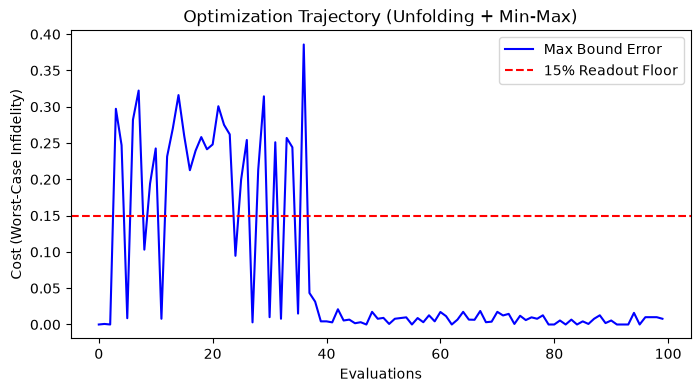

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator
from qiskit_algorithms.optimizers import COBYLA

# 1. Construct parameterized ansatz
# Count total num of parameters for decomposed circuit
num_params = len(GATES)
theta = ParameterVector('theta', num_params)

ansatz = QuantumCircuit(3)
initial_angles = []
param_idx = 0

for gate_name, qubits, angle in GATES:
    initial_angles.append(angle)
    getattr(ansatz, gate_name)(theta[param_idx], *qubits)
    param_idx += 1

initial_angles = np.array(initial_angles)

# 2. Define unfolding matrix
C = np.array([[0.99, 0.15],
              [0.01, 0.85]])
M = np.kron(C, np.kron(C, C))
M_inv = np.linalg.inv(M)

# 3. Define robust cost function
def robust_unfolded_cost_function(theta_vals):
    errors = []

    # Toffoli Truth Table where q0 is the target (flips when q2 and q1 are '1')
    truth_table = {
        '000': '000', '001': '001', '010': '010', '011': '011',
        '100': '100', '101': '101', '110': '111', '111': '110'
    }

    # Bind parameters w/ dictionary mapping
    param_dict = dict(zip(theta, theta_vals))
    bound_ansatz = ansatz.assign_parameters(param_dict)

    for input_state, expected_out in truth_table.items():
        qc = QuantumCircuit(3)

        # Prepare state
        if input_state[0] == '1': qc.x(2)
        if input_state[1] == '1': qc.x(1)
        if input_state[2] == '1': qc.x(0)

        # Append parameterized ansatz
        qc = qc.compose(bound_ansatz)
        qc.measure_all()

        # Execute
        counts = sim.run(qc, shots=shots).result().get_counts()

        # Vectorize counts
        p_noisy = np.zeros(8)
        for bitstring, count in counts.items():
            p_noisy[int(bitstring, 2)] = count / shots

        # Unfold classical hardware bias
        p_true = np.dot(M_inv, p_noisy)

        # Calculate isolated gate error
        target_idx = int(expected_out, 2)
        success_prob = np.clip(p_true[target_idx], 0.0, 1.0)
        errors.append(1.0 - success_prob)

    # Return max error; min - max bound
    cost_history.append(np.max(errors))
    return np.max(errors)

# 4. Pipeline execution
cost_history = []
def spsa_callback(n_fevs, x_next, fx_next, stepsize, accepted):
    cost_history.append(fx_next)
    if n_fevs % 10 == 0:
        print(f"Iteration {n_fevs}: Worst-Case Error = {fx_next:.4f}")

print(f"Starting SPSA Optimization mapping {num_params} parameters...")
# Use original angles as start
optimizer = COBYLA(maxiter = 100)
result = optimizer.minimize(fun=robust_unfolded_cost_function, x0=initial_angles)
optimal_angles = result.x

# 5. Trajectory plotting
plt.figure(figsize=(8, 4))
plt.plot(cost_history, label='Max Bound Error', color='blue')
plt.axhline(y=0.15, color='r', linestyle='--', label="15% Readout Floor")
plt.title("Optimization Trajectory (Unfolding + Min-Max)")
plt.xlabel("Evaluations")
plt.ylabel("Cost (Worst-Case Infidelity)")
plt.legend()
plt.show()

Evaluating optimal circuit across different shot counts...
Shots:   100 | Worst-Case Error: 0.0004
Shots:   500 | Worst-Case Error: 0.0000
Shots:  1000 | Worst-Case Error: 0.0090
Shots:  2000 | Worst-Case Error: 0.0029
Shots:  5000 | Worst-Case Error: 0.0026
Shots: 10000 | Worst-Case Error: 0.0051
Shots: 20000 | Worst-Case Error: 0.0030
Shots: 40000 | Worst-Case Error: 0.0027
Shots: 80000 | Worst-Case Error: 0.0038
Shots: 160000 | Worst-Case Error: 0.0047
Shots: 480000 | Worst-Case Error: 0.0043
Shots: 1000000 | Worst-Case Error: 0.0041


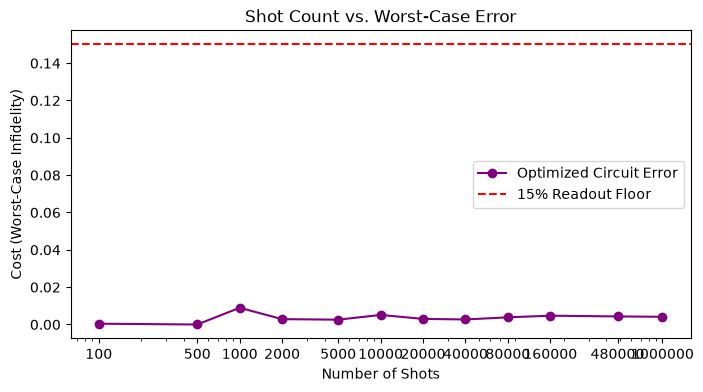

: 

In [ ]:
# 6. Shot Scaling Analysis (Run in a separate cell!)
import matplotlib.pyplot as plt

shot_counts = [100, 500, 1000, 2000, 5000, 10000, 20000, 40000, 80000, 160000, 480000, 1000000]
shot_costs = []

print("Evaluating optimal circuit across different shot counts...")

for shots in shot_counts:
    # Pass the optimal angles and the new shot count directly into your function
    cost = robust_unfolded_cost_function(optimal_angles)
    shot_costs.append(cost)
    print(f"Shots: {shots:5d} | Worst-Case Error: {cost:.4f}")

# Generate the NEW plot
plt.figure(figsize=(8, 4))
plt.plot(shot_counts, shot_costs, marker='o', linestyle='-', color='purple', label='Optimized Circuit Error')
plt.axhline(y=0.15, color='r', linestyle='--', label="15% Readout Floor")
plt.title("Shot Count vs. Worst-Case Error")
plt.xlabel("Number of Shots")
plt.ylabel("Cost (Worst-Case Infidelity)")
plt.xscale('log') 
plt.xticks(shot_counts, labels=[str(s) for s in shot_counts])
plt.legend()
plt.show()

## Hardware submissions: `new_design` and `model3` (recovered)

These cells were run on the night of 24 Oct but never saved to the notebook; they are recovered verbatim from the kernel's IPython history. **They have already been submitted: do not rerun them** (each one refuses to overwrite its existing queue-ID file anyway).

- `new_design` was built from the `GATES` defined at the time, which was `cand`'s list, so it is the same circuit as `candidate`.
- `model3` is the 5-`rxx` circuit at −0.511π, ±0.250π, −0.511π, π/4. A third copy that only changed the file name to `model3.1_Fxxx` left an empty queue-ID file and is not included.

In [ ]:
# RECOVERED from kernel history: new_design, F_XXX (16 circuits x 64 shots). ALREADY SUBMITTED, DO NOT RERUN.
import json
import os
import numpy as np
from qiskit import QuantumCircuit
from toffoli_challenge import (
    validate_submission_circuit,
    submit_circuit,
    remaining_hardware_shots
)

# ============================================================
# 1. Build the new Toffoli candidate
# ============================================================

pi = np.pi

def build_new_model(gates):
    qc = QuantumCircuit(3)

    for name, qubits, angle in gates:
        if name == "rxx":
            qc.rxx(angle, *qubits)
        else:
            getattr(qc, name)(angle, qubits[0])

    return qc

candidate = build_new_model(GATES)
validate_submission_circuit(candidate)

# ============================================================
# 2. Prepare X-basis inputs and measurement rotations
# ============================================================

def make_fxxx_circuit(candidate, bits, axes):
    qc = QuantumCircuit(3)

    # Prepare X eigenstates, ordered q2 q1 q0
    for q, bit in zip([2, 1, 0], bits):
        qc.ry(
            np.pi / 2 if bit == "0" else -np.pi / 2,
            q
        )

    # Apply candidate Toffoli
    qc.compose(candidate, inplace=True)

    # Rotate measurement bases to Z
    for q, axis in zip([2, 1, 0], axes):
        if axis == "X":
            qc.ry(-np.pi / 2, q)
        elif axis == "Y":
            qc.rx(np.pi / 2, q)

    validate_submission_circuit(qc)
    return qc

# ============================================================
# 3. Generate 16 measurement circuits
# ============================================================

experiments = {}

for i in range(8):
    bits = format(i, "03b")

    if bits[2] == "0":
        axes_list = ["XXX"]
    else:
        axes_list = ["XZX", "ZXX", "YYX"]

    for axes in axes_list:
        experiments[(bits, axes)] = make_fxxx_circuit(
            candidate, bits, axes
        )

SHOTS = 64
FILENAME = "new_design_Fxxx_1024_queue_ids.json"

assert len(experiments) == 16
assert len(experiments) * SHOTS == 1024

# ============================================================
# 4. Check budget and prevent duplicate submissions
# ============================================================

for circuit in experiments.values():
    validate_submission_circuit(circuit)

status = remaining_hardware_shots()

print("=== F_XXX SUBMISSION PLAN ===")
print("Circuits:", len(experiments))
print("Shots per circuit:", SHOTS)
print("Total shots:", len(experiments) * SHOTS)
print("Available:", status["hardware_shots_remaining"])

assert status["hardware_shots_remaining"] >= 1024

if os.path.exists(FILENAME):
    raise FileExistsError(
        f"{FILENAME} already exists. "
        "Rename or archive it before submitting again."
    )

# ============================================================
# 5. Submit and save queue IDs
# ============================================================

records = []

with open(FILENAME, "w") as f:
    json.dump(records, f, indent=2)

for (bits, axes), circuit in experiments.items():
    receipt = submit_circuit(circuit, shots=SHOTS)
    qid = receipt["submission"]["queue_id"]

    records.append({
        "input": bits,
        "axes": axes,
        "queue_id": qid,
        "shots": SHOTS
    })

    # Save after every successful submission
    with open(FILENAME, "w") as f:
        json.dump(records, f, indent=2)

    print(
        f"F_XXX | Input: {bits} | "
        f"Basis: {axes} | Queue: {qid}"
    )

# ============================================================
# 6. Summary
# ============================================================

print("\n=== F_XXX SUBMISSION COMPLETE ===")
print("Jobs submitted:", len(records))
print("Total submitted shots:", len(records) * SHOTS)
print("Saved queue IDs to:", FILENAME)
print(
    "Remaining shots:",
    remaining_hardware_shots()["hardware_shots_remaining"]
)

: 

In [ ]:
# RECOVERED from kernel history: new_design, F_ZZZ (8 circuits x 128 shots). ALREADY SUBMITTED, DO NOT RERUN.
import json
import os
import numpy as np
from qiskit import QuantumCircuit
from toffoli_challenge import (
    validate_submission_circuit,
    submit_circuit,
    remaining_hardware_shots
)

# ============================================================
# 1. Build the new Toffoli candidate
# ============================================================

pi = np.pi

def build_new_model(gates):
    qc = QuantumCircuit(3)

    for name, qubits, angle in gates:
        if name == "rxx":
            qc.rxx(angle, *qubits)
        else:
            getattr(qc, name)(angle, qubits[0])

    return qc

candidate = build_new_model(GATES)
validate_submission_circuit(candidate)

# ============================================================
# 2. Prepare computational-basis input circuits
# ============================================================

def make_fzzz_circuit(candidate, bits):
    qc = QuantumCircuit(3)

    # Prepare |q2 q1 q0>
    for q, bit in zip([2, 1, 0], bits):
        if bit == "1":
            qc.rx(np.pi, q)

    # Apply candidate Toffoli
    qc.compose(candidate, inplace=True)

    validate_submission_circuit(qc)
    return qc

# ============================================================
# 3. Generate all 8 Z-basis input circuits
# ============================================================

experiments = {
    format(i, "03b"): make_fzzz_circuit(
        candidate, format(i, "03b")
    )
    for i in range(8)
}

SHOTS = 128
FILENAME = "new_design_Fzzz_1024_queue_ids.json"

assert len(experiments) == 8
assert len(experiments) * SHOTS == 1024

# ============================================================
# 4. Check budget and prevent duplicate submissions
# ============================================================

for circuit in experiments.values():
    validate_submission_circuit(circuit)

status = remaining_hardware_shots()

print("=== F_ZZZ SUBMISSION PLAN ===")
print("Circuits:", len(experiments))
print("Shots per circuit:", SHOTS)
print("Total shots:", len(experiments) * SHOTS)
print("Available:", status["hardware_shots_remaining"])

assert status["hardware_shots_remaining"] >= 1024

if os.path.exists(FILENAME):
    raise FileExistsError(
        f"{FILENAME} already exists. "
        "Rename or archive it before submitting again."
    )

# ============================================================
# 5. Submit and save queue IDs
# ============================================================

records = []

with open(FILENAME, "w") as f:
    json.dump(records, f, indent=2)

for bits, circuit in experiments.items():
    receipt = submit_circuit(circuit, shots=SHOTS)
    qid = receipt["submission"]["queue_id"]

    # Ideal Toffoli output: flip q0 if q2=q1=1
    if bits[:2] == "11":
        expected = bits[:2] + str(1 - int(bits[2]))
    else:
        expected = bits

    records.append({
        "input": bits,
        "expected_output": expected,
        "queue_id": qid,
        "shots": SHOTS
    })

    # Save after every successful submission
    with open(FILENAME, "w") as f:
        json.dump(records, f, indent=2)

    print(
        f"F_ZZZ | Input: {bits} | "
        f"Expected: {expected} | Queue: {qid}"
    )

# ============================================================
# 6. Summary
# ============================================================

print("\n=== F_ZZZ SUBMISSION COMPLETE ===")
print("Jobs submitted:", len(records))
print("Total submitted shots:", len(records) * SHOTS)
print("Saved queue IDs to:", FILENAME)
print(
    "Remaining shots:",
    remaining_hardware_shots()["hardware_shots_remaining"]
)

: 

In [ ]:
# RECOVERED from kernel history: model3, F_XXX (16 circuits x 64 shots). ALREADY SUBMITTED, DO NOT RERUN.
import json
import os
import numpy as np
from numpy import pi
from qiskit import QuantumCircuit
from toffoli_challenge import (
    validate_submission_circuit,
    submit_circuit,
    remaining_hardware_shots
)

# ============================================================
# 1. Define the new 20-gate Toffoli model
# ============================================================

GATES = [
    ("rz",  (0,),    0.489039403306*pi),
    ("rz",  (1,),   -pi/4),
    ("ry",  (1,),    pi/2),
    ("rxx", (0, 1), -0.510954104576*pi),
    ("rz",  (0,),   -0.750188632588*pi),
    ("ry",  (0,),   -pi/2),
    ("ry",  (2,),    pi/2),
    ("rz",  (0,),    0.984523820463*pi),
    ("rxx", (0, 2),  0.250376818829*pi),
    ("rz",  (0,),    0.510934666597*pi),
    ("rxx", (0, 1), -0.510954104576*pi),
    ("rz",  (0,),    0.249811367412*pi),
    ("ry",  (0,),    pi/2),
    ("rz",  (0,),    0.984523820463*pi),
    ("rxx", (0, 2), -0.250376818829*pi),
    ("rz",  (0,),   -0.978104736709*pi),
    ("rxx", (1, 2),  pi/4),
    ("ry",  (1,),   -pi/2),
    ("ry",  (2,),   -pi/2),
    ("rz",  (2,),   -pi/4),
]

def build_model(gates):
    qc = QuantumCircuit(3)
    for name, qubits, angle in gates:
        if name == "rxx":
            qc.rxx(angle, *qubits)
        else:
            getattr(qc, name)(angle, qubits[0])
    return qc

candidate = build_model(GATES)
validate_submission_circuit(candidate)

# ============================================================
# 2. Prepare X-basis inputs and measurements
# ============================================================

def make_fxxx_circuit(candidate, bits, axes):
    qc = QuantumCircuit(3)

    # Prepare X eigenstates (q2 q1 q0)
    for q, bit in zip([2, 1, 0], bits):
        qc.ry(
            pi/2 if bit == "0" else -pi/2,
            q
        )

    qc.compose(candidate, inplace=True)

    # Rotate requested measurement bases into Z
    for q, axis in zip([2, 1, 0], axes):
        if axis == "X":
            qc.ry(-pi/2, q)
        elif axis == "Y":
            qc.rx(pi/2, q)

    validate_submission_circuit(qc)
    return qc

# ============================================================
# 3. Generate 16 measurement circuits
# ============================================================

experiments = {}

for i in range(8):
    bits = format(i, "03b")

    axes_list = (
        ["XXX"]
        if bits[2] == "0"
        else ["XZX", "ZXX", "YYX"]
    )

    for axes in axes_list:
        experiments[(bits, axes)] = make_fxxx_circuit(
            candidate, bits, axes
        )

SHOTS = 64
FILENAME = "model3_Fxxx_1024_queue_ids.json"

assert len(experiments) == 16
assert len(experiments) * SHOTS == 1024

# ============================================================
# 4. Check hardware budget
# ============================================================

for circuit in experiments.values():
    validate_submission_circuit(circuit)

status = remaining_hardware_shots()

print("=== MODEL 3 F_XXX ===")
print("Circuits:", len(experiments))
print("Shots per circuit:", SHOTS)
print("Total shots:", len(experiments) * SHOTS)
print("Available:", status["hardware_shots_remaining"])

assert status["hardware_shots_remaining"] >= 1024

if os.path.exists(FILENAME):
    raise FileExistsError(
        f"{FILENAME} already exists. "
        "Rename or archive it before submitting again."
    )

# ============================================================
# 5. Submit and save queue IDs
# ============================================================

records = []

with open(FILENAME, "w") as f:
    json.dump(records, f, indent=2)

for (bits, axes), circuit in experiments.items():
    receipt = submit_circuit(circuit, shots=SHOTS)
    qid = receipt["submission"]["queue_id"]

    records.append({
        "input": bits,
        "axes": axes,
        "queue_id": qid,
        "shots": SHOTS
    })

    with open(FILENAME, "w") as f:
        json.dump(records, f, indent=2)

    print(f"F_XXX | {bits} | {axes} | Queue: {qid}")

print("\n=== F_XXX SUBMISSION COMPLETE ===")
print("Jobs submitted:", len(records))
print("Total shots:", len(records) * SHOTS)
print("Saved to:", FILENAME)
print(
    "Remaining hardware shots:",
    remaining_hardware_shots()["hardware_shots_remaining"]
)

: 

In [ ]:
# RECOVERED from kernel history: model3, F_ZZZ (8 circuits x 128 shots). ALREADY SUBMITTED, DO NOT RERUN.
import json
import os
import numpy as np
from numpy import pi
from qiskit import QuantumCircuit
from toffoli_challenge import (
    validate_submission_circuit,
    submit_circuit,
    remaining_hardware_shots
)

# ============================================================
# 1. Define the new 20-gate Toffoli model
# ============================================================

GATES = [
    ("rz",  (0,),    0.489039403306*pi),
    ("rz",  (1,),   -pi/4),
    ("ry",  (1,),    pi/2),
    ("rxx", (0, 1), -0.510954104576*pi),
    ("rz",  (0,),   -0.750188632588*pi),
    ("ry",  (0,),   -pi/2),
    ("ry",  (2,),    pi/2),
    ("rz",  (0,),    0.984523820463*pi),
    ("rxx", (0, 2),  0.250376818829*pi),
    ("rz",  (0,),    0.510934666597*pi),
    ("rxx", (0, 1), -0.510954104576*pi),
    ("rz",  (0,),    0.249811367412*pi),
    ("ry",  (0,),    pi/2),
    ("rz",  (0,),    0.984523820463*pi),
    ("rxx", (0, 2), -0.250376818829*pi),
    ("rz",  (0,),   -0.978104736709*pi),
    ("rxx", (1, 2),  pi/4),
    ("ry",  (1,),   -pi/2),
    ("ry",  (2,),   -pi/2),
    ("rz",  (2,),   -pi/4),
]

def build_model(gates):
    qc = QuantumCircuit(3)
    for name, qubits, angle in gates:
        if name == "rxx":
            qc.rxx(angle, *qubits)
        else:
            getattr(qc, name)(angle, qubits[0])
    return qc

candidate = build_model(GATES)
validate_submission_circuit(candidate)

# ============================================================
# 2. Prepare computational-basis inputs
# ============================================================

def make_fzzz_circuit(candidate, bits):
    qc = QuantumCircuit(3)

    # Prepare |q2 q1 q0>
    for q, bit in zip([2, 1, 0], bits):
        if bit == "1":
            qc.rx(pi, q)

    qc.compose(candidate, inplace=True)

    validate_submission_circuit(qc)
    return qc

# ============================================================
# 3. Generate all 8 computational-basis circuits
# ============================================================

experiments = {
    format(i, "03b"): make_fzzz_circuit(
        candidate, format(i, "03b")
    )
    for i in range(8)
}

SHOTS = 128
FILENAME = "model3_Fzzz_1024_queue_ids.json"

assert len(experiments) == 8
assert len(experiments) * SHOTS == 1024

# ============================================================
# 4. Check hardware budget
# ============================================================

for circuit in experiments.values():
    validate_submission_circuit(circuit)

status = remaining_hardware_shots()

print("=== MODEL 3 F_ZZZ ===")
print("Circuits:", len(experiments))
print("Shots per circuit:", SHOTS)
print("Total shots:", len(experiments) * SHOTS)
print("Available:", status["hardware_shots_remaining"])

assert status["hardware_shots_remaining"] >= 1024

if os.path.exists(FILENAME):
    raise FileExistsError(
        f"{FILENAME} already exists. "
        "Rename or archive it before submitting again."
    )

# ============================================================
# 5. Submit and save queue IDs
# ============================================================

records = []

with open(FILENAME, "w") as f:
    json.dump(records, f, indent=2)

for bits, circuit in experiments.items():
    receipt = submit_circuit(circuit, shots=SHOTS)
    qid = receipt["submission"]["queue_id"]

    # Ideal Toffoli output
    expected = (
        bits[:2] + str(1 - int(bits[2]))
        if bits[:2] == "11"
        else bits
    )

    records.append({
        "input": bits,
        "expected_output": expected,
        "queue_id": qid,
        "shots": SHOTS
    })

    with open(FILENAME, "w") as f:
        json.dump(records, f, indent=2)

    print(
        f"F_ZZZ | {bits} -> {expected} | Queue: {qid}"
    )

print("\n=== F_ZZZ SUBMISSION COMPLETE ===")
print("Jobs submitted:", len(records))
print("Total shots:", len(records) * SHOTS)
print("Saved to:", FILENAME)
print(
    "Remaining hardware shots:",
    remaining_hardware_shots()["hardware_shots_remaining"]
)

: 

## IonQ Forte-1: our circuits, original and optimized with the teammate's phase-aware cost

For each circuit:

1. **Original on IonQ:** one job on IonQ's simulator with the **`forte-1` noise model** (all 8 truth-table inputs).
2. **Teammate's phase-aware optimization, locally:** COBYLA (200 iterations) minimizing 1 − average gate fidelity between the circuit's exact unitary and the ideal Toffoli. This cost sees relative phases, so the result stays a Toffoli, but it uses no noise model.
3. **Optimized on IonQ:** one more Forte-1 job with the optimized angles.

The setup cell asks for the **team name** (used in IonQ job names, job metadata, plot titles and the log file `ionq_jobs_<team>.json`) and your IonQ API key. Every run prints its ideal process fidelity with the Toffoli; anything below 0.99 is flagged as no longer a Toffoli.

In [23]:
# For each of our circuits:
#   1. optimize its angles with the TEAMMATE'S phase-aware cost: 1 - average gate fidelity with the
#      ideal Toffoli (exact unitary, noise-free), minimized with COBYLA (200 iterations);
#   2. run the ORIGINAL and the OPTIMIZED circuit on IonQ's simulator with the Forte-1 noise model.
# IonQ's cloud simulator only accepts IonQ's own noise models, so step 1 runs locally on Aer.
# Needs: python -m pip install -r requirements-ionq.txt, and your IonQ API key (never commit it).
import os
import warnings
from getpass import getpass

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXXGate
from qiskit.quantum_info import Operator, average_gate_fidelity
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, coherent_unitary_error, depolarizing_error
from qiskit_ionq import IonQProvider
from qiskit_ionq.exceptions import IonQTranspileLevelWarning
from scipy.optimize import minimize   # same COBYLA that qiskit_algorithms wraps

from toffoli_challenge import (
    TOFFOLI_INPUTS,
    compare_to_toffoli,
    expected_output_bitstring,
    ideal_toffoli_in_submission_order,
)
from toffoli_challenge.ionq import (
    IONQ_NOISE_MODEL,
    record_job,
    run_without_debiasing,
    truth_table_circuits,
    truth_table_from_job,
)
TEAM_NAME = 'team_1'
IONQ_API_KEY = 'tssC1iCOQBLqNTIAmE6IvDdyqNp10AXd'

# TEAM_NAME = input('Team name: ').strip() or 'unnamed-team'
# IONQ_API_KEY = (os.environ.get('IONQ_API_KEY') or getpass('Paste your IonQ API key: ')).strip()
if not IONQ_API_KEY:
    raise ValueError('No IonQ API key entered: create one at cloud.ionq.com in your team project.')
# IonQ warns that Qiskit's default transpile level is 2; these cells never call transpile(),
# so the warning does not apply here.
warnings.filterwarnings('ignore', category=IonQTranspileLevelWarning)
ionq_sim = IonQProvider(token=IONQ_API_KEY).get_backend('simulator')     # noise model 'forte-1' is passed on every run
IONQ_JOB_LOG = f'ionq_jobs_{TEAM_NAME}.json'

IONQ_SHOTS = 1024
LOCAL_SHOTS = 1024
LOCAL_MAXITER = 200   # as in the teammate's phase-aware optimizer

# ---------------------------------------------------------------- teammate's noise model and cost
# Same model as the teammate's cell: 0.1% depolarizing on rx/ry, a +0.2 rad rxx over-rotation,
# and readout P(1|0) = 1%, P(0|1) = 5%.
teammate_noise_model = NoiseModel()
teammate_noise_model.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ['rx', 'ry'])
teammate_noise_model.add_all_qubit_quantum_error(coherent_unitary_error(RXXGate(0.2).to_matrix()), ['rxx'])
teammate_noise_model.add_all_qubit_readout_error(ReadoutError([[0.99, 0.01], [0.05, 0.95]]))
teammate_sim = AerSimulator(noise_model=teammate_noise_model)

# Same readout-unfolding matrix as the teammate's optimizer.
C = np.array([[0.99, 0.15],
              [0.01, 0.85]])
M_inv = np.linalg.inv(np.kron(C, np.kron(C, C)))


def build_ansatz(gates):
    """Every gate angle in `gates` becomes a free parameter, started at its current value."""
    theta = ParameterVector('theta', len(gates))
    ansatz = QuantumCircuit(3)
    for k, (name, qubits, _) in enumerate(gates):
        getattr(ansatz, name)(theta[k], *qubits)
    return ansatz, theta, np.array([angle for _, _, angle in gates], dtype=float)


def circuit_from_gates(gates):
    ansatz, theta, angles = build_ansatz(gates)
    return ansatz.assign_parameters(dict(zip(theta, angles)))


def teammate_cost(circuit, shots=LOCAL_SHOTS):
    """The teammate's robust_unfolded_cost_function for one bound circuit: worst-case unfolded error."""
    errors = []
    for input_bits in TOFFOLI_INPUTS:
        qc = QuantumCircuit(3)
        for q, bit in zip([2, 1, 0], input_bits):
            if bit == '1':
                qc.x(q)
        qc = qc.compose(circuit)
        qc.measure_all()
        counts = teammate_sim.run(qc, shots=shots).result().get_counts()
        p_noisy = np.zeros(8)
        for bits, count in counts.items():
            p_noisy[int(bits, 2)] = count / shots
        p_true = M_inv @ p_noisy
        success = np.clip(p_true[int(expected_output_bitstring(input_bits), 2)], 0.0, 1.0)
        errors.append(1.0 - success)
    return float(np.max(errors))


# Teammate's PHASE-AWARE cost (replaces teammate_cost above in the optimizer): 1 - average gate
# fidelity between the circuit's exact unitary and the ideal Toffoli. It sees relative phases,
# but it is noise-free: no noise model, shots or readout unfolding are involved.
IDEAL_TOFFOLI = Operator(ideal_toffoli_in_submission_order())


def phase_aware_cost(circuit):
    return 1.0 - average_gate_fidelity(Operator(circuit), IDEAL_TOFFOLI)


def optimize_with_teammate_model(label, gates, maxiter=LOCAL_MAXITER):
    """COBYLA over every angle with the teammate's phase-aware cost; returns the optimized gate list."""
    ansatz, theta, x0 = build_ansatz(gates)
    history = []

    def cost(theta_vals):
        history.append(phase_aware_cost(ansatz.assign_parameters(dict(zip(theta, theta_vals)))))
        return history[-1]

    result = minimize(cost, x0, method='COBYLA', options={'maxiter': maxiter})
    optimized_gates = [(name, qubits, float(angle)) for (name, qubits, _), angle in zip(gates, result.x)]
    _, fidelity, _ = compare_to_toffoli(circuit_from_gates(optimized_gates))
    print(f'{label}: phase-aware cost {history[0]:.2e} -> {result.fun:.2e} after {len(history)} evaluations; '
          f'ideal process fidelity after optimization {fidelity:.6f}'
          + ('' if fidelity > 0.99 else '   <-- NO LONGER A TOFFOLI, do not submit'))

    plt.figure(figsize=(8, 4))
    plt.plot(history, color='blue', label='1 - average gate fidelity')
    plt.yscale('log')
    plt.title(f'{TEAM_NAME} | {label}: phase-aware optimization')
    plt.xlabel('Evaluations')
    plt.ylabel('Cost (gate infidelity)')
    plt.legend()
    plt.show()
    return optimized_gates, fidelity


# ---------------------------------------------------------------- IonQ Forte-1 runs
ionq_tests = {}


def run_on_ionq_forte(label, gates, shots=IONQ_SHOTS):
    """One IonQ job: all 8 truth-table inputs on the Forte-1 noisy simulator, tagged with the team name.
    The job ID is logged to IONQ_JOB_LOG so every number can be traced like a lab queue ID."""
    circuit = circuit_from_gates(gates)
    _, process_fidelity, _ = compare_to_toffoli(circuit)
    job_name = f'{TEAM_NAME} | {label}'
    job = run_without_debiasing(ionq_sim, truth_table_circuits(circuit), shots=shots,
                                noise_model=IONQ_NOISE_MODEL, name=job_name,
                                extra_metadata={'team': TEAM_NAME, 'model': label})
    record_job(job, ionq_sim.name, label=job_name, shots=shots, path=IONQ_JOB_LOG,
               team=TEAM_NAME, noise_model=IONQ_NOISE_MODEL)
    report = truth_table_from_job(job)
    probs = [entry.success_probability for entry in report.per_input.values()]
    se = float(np.sqrt(sum(p * (1 - p) / shots for p in probs)) / 8)
    print(f'{label}: IonQ job {job.job_id()}; ideal process fidelity {process_fidelity:.6f}')
    print(f'{label}: Forte-1 truth-table success {report.mean_success_probability:.4f} +/- {se:.4f}')
    for input_bits, entry in report.per_input.items():
        print(f'    {input_bits} -> {entry.ideal_output}: {entry.success_probability:.4f}')
    ionq_tests[label] = {'mean': report.mean_success_probability, 'se': se,
                         'process_fidelity': process_fidelity, 'job_id': job.job_id()}
    return report


def run_model(label, gates, optimize=True):
    """Original on IonQ, then teammate optimization, then optimized on IonQ."""
    print('=' * 78)
    print(f'TEAM {TEAM_NAME}  |  {label}  |  IonQ simulator, noise model {IONQ_NOISE_MODEL}')
    print('=' * 78)
    run_on_ionq_forte(f'{label} (original)' if optimize else label, gates)
    if not optimize:
        return None
    optimized_gates, _ = optimize_with_teammate_model(label, gates)
    run_on_ionq_forte(f'{label} (optimized, phase-aware)', optimized_gates)
    return optimized_gates

### Model 1: 35-gate circuit (`cand`)

5 `rxx` at ±π/3 and π/4 (total entangling angle 1.58π), 7 `ry`. Hardware runs: `candidate_Fzzz`, `reference1_Fxxx`, `new_design_Fzzz`, `new_design_Fxxx`.

TEAM team_1  |  MODEL 1: cand  |  IonQ simulator, noise model forte-1
MODEL 1: cand (original): IonQ job 01a17323-8b29-774a-a3c5-841451916f33; ideal process fidelity 1.000000
MODEL 1: cand (original): Forte-1 truth-table success 0.9999 +/- 0.0001
    000 -> 000: 1.0000
    001 -> 001: 1.0000
    010 -> 010: 1.0000
    011 -> 011: 1.0000
    100 -> 100: 1.0000
    101 -> 101: 1.0000
    110 -> 111: 0.9990
    111 -> 110: 1.0000
MODEL 1: cand: phase-aware cost 7.77e-16 -> 7.77e-16 after 189 evaluations; ideal process fidelity after optimization 1.000000


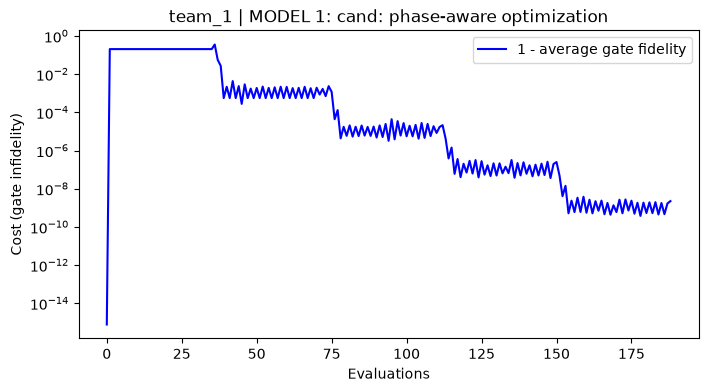

MODEL 1: cand (optimized, phase-aware): IonQ job 01a17323-bbab-7329-98f8-9d3aeefd3397; ideal process fidelity 1.000000
MODEL 1: cand (optimized, phase-aware): Forte-1 truth-table success 0.9993 +/- 0.0003
    000 -> 000: 1.0000
    001 -> 001: 1.0000
    010 -> 010: 1.0000
    011 -> 011: 0.9971
    100 -> 100: 1.0000
    101 -> 101: 0.9980
    110 -> 111: 1.0000
    111 -> 110: 0.9990


In [24]:
# IonQ Forte-1 noisy simulator, MODEL 1: our candidate (cand).
# Same circuit as the hardware runs candidate_Fzzz, reference1_Fxxx and new_design_Fzzz/Fxxx.
CAND_GATES = [
    ("rz", (0,), -0.695913261 * np.pi), ("rz", (1,), -3 * np.pi / 4), ("ry", (1,), np.pi / 2),
    ("rz", (1,), -np.pi), ("rz", (2,), 2 * np.pi / 3),
    ("rxx", (0, 1), np.pi / 3),
    ("rz", (0,), 0.804086709 * np.pi), ("ry", (0,), -np.pi / 2), ("rz", (0,), -0.195913283 * np.pi),
    ("rz", (1,), -5 * np.pi / 12), ("rz", (2,), np.pi / 6), ("ry", (2,), np.pi / 2), ("rz", (2,), -np.pi),
    ("rxx", (0, 2), -np.pi / 3),
    ("rz", (0,), 0.608173462 * np.pi), ("rz", (1,), 5 * np.pi / 12), ("rz", (2,), -5 * np.pi / 12),
    ("rxx", (0, 1), np.pi / 3),
    ("rz", (0,), -0.547947298 * np.pi), ("ry", (0,), -0.320577980 * np.pi), ("rz", (0,), -np.pi / 12),
    ("rz", (1,), -np.pi / 3), ("rz", (2,), -7 * np.pi / 12),
    ("rxx", (0, 2), -np.pi / 3),
    ("rz", (0,), -np.pi / 12), ("rz", (1,), -2 * np.pi / 3),
    ("rxx", (1, 2), np.pi / 4),
    ("rz", (0,), -np.pi), ("ry", (0,), -0.679422045 * np.pi), ("rz", (0,), 0.852033996 * np.pi),
    ("ry", (1,), -np.pi / 2), ("rz", (1,), np.pi / 2), ("rz", (2,), -np.pi), ("ry", (2,), np.pi / 2),
    ("rz", (2,), -np.pi / 12),
]

optimized_gates_cand = run_model('MODEL 1: cand', CAND_GATES)

### Model 3: 20-gate circuit (`model 3`)

Same structure as `cand` with asymmetric angles: `rxx` at −0.511π, ±0.250π, −0.511π and π/4 (total 1.77π), 6 `ry`. Hardware runs: `model3_Fzzz`, `model3_Fxxx`.

TEAM team_1  |  MODEL 3: 20-gate  |  IonQ simulator, noise model forte-1
MODEL 3: 20-gate (original): IonQ job 01a17324-bb9d-7784-8bcb-90fea5d92d7f; ideal process fidelity 1.000000
MODEL 3: 20-gate (original): Forte-1 truth-table success 1.0000 +/- 0.0000
    000 -> 000: 1.0000
    001 -> 001: 1.0000
    010 -> 010: 1.0000
    011 -> 011: 1.0000
    100 -> 100: 1.0000
    101 -> 101: 1.0000
    110 -> 111: 1.0000
    111 -> 110: 1.0000
MODEL 3: 20-gate: phase-aware cost 4.44e-16 -> 4.44e-16 after 114 evaluations; ideal process fidelity after optimization 1.000000


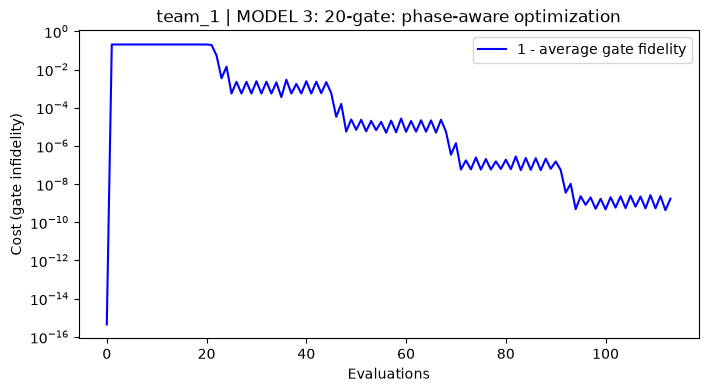

In [ ]:
# IonQ Forte-1 noisy simulator, MODEL 2: the 20-gate circuit ('model 3'; hardware runs model3_Fzzz, model3_Fxxx).
# Keep every digit: the circuit is an exact Toffoli only with these values.
MODEL3_GATES = [
    ("rz", (0,), 0.489039403306 * np.pi), ("rz", (1,), -np.pi / 4), ("ry", (1,), np.pi / 2),
    ("rxx", (0, 1), -0.510954104576 * np.pi),
    ("rz", (0,), -0.750188632588 * np.pi), ("ry", (0,), -np.pi / 2), ("ry", (2,), np.pi / 2),
    ("rz", (0,), 0.984523820463 * np.pi),
    ("rxx", (0, 2), 0.250376818829 * np.pi),
    ("rz", (0,), 0.510934666597 * np.pi),
    ("rxx", (0, 1), -0.510954104576 * np.pi),
    ("rz", (0,), 0.249811367412 * np.pi), ("ry", (0,), np.pi / 2), ("rz", (0,), 0.984523820463 * np.pi),
    ("rxx", (0, 2), -0.250376818829 * np.pi),
    ("rz", (0,), -0.978104736709 * np.pi),
    ("rxx", (1, 2), np.pi / 4),
    ("ry", (1,), -np.pi / 2), ("ry", (2,), -np.pi / 2), ("rz", (2,), -np.pi / 4),
]

optimized_gates_model3 = run_model('MODEL 3: 20-gate', MODEL3_GATES)

### Model 2: 29-gate circuit

Same structure again: `rxx` at +0.483π, −0.517π, +0.483π, −0.517π and π/4 (total 2.25π), 5 `ry` and 2 `rx`. Exact Toffoli (ideal process fidelity 1.0).

In [ ]:
# IonQ Forte-1 noisy simulator, MODEL 3: the 29-gate circuit.
# Keep every digit: the circuit is an exact Toffoli only with these values.
GATES_29 = [
    ("rz", (0,), -0.517038623008 * np.pi), ("rz", (1,), +0.788010090116 * np.pi), ("rx", (1,), +0.500000000000 * np.pi),
    ("rz", (1,), -0.500000000000 * np.pi), ("rz", (2,), +0.798679176017 * np.pi),
    ("rxx", (0, 1), +0.482985734979 * np.pi),
    ("rz", (0,), +0.250455590464 * np.pi), ("rx", (0,), -0.499999999999 * np.pi), ("rz", (0,), -0.982432435245 * np.pi),
    ("ry", (2,), +0.500000000000 * np.pi), ("rz", (2,), -1.000000000000 * np.pi),
    ("rxx", (0, 2), -0.517490831696 * np.pi),
    ("rz", (0,), +0.250938495093 * np.pi), ("rz", (2,), -1.000000000000 * np.pi),
    ("rxx", (0, 1), +0.482985734979 * np.pi),
    ("rz", (0,), -0.299028021537 * np.pi), ("ry", (0,), -0.320865831169 * np.pi), ("rz", (0,), +0.184131340716 * np.pi),
    ("rz", (1,), -1.000000000000 * np.pi),
    ("rxx", (0, 2), -0.517490831696 * np.pi),
    ("rz", (0,), +0.197464156016 * np.pi),
    ("rxx", (1, 2), +0.250000000000 * np.pi),
    ("ry", (0,), -0.663258958518 * np.pi), ("rz", (0,), +0.833282316680 * np.pi), ("ry", (1,), -0.500000000000 * np.pi),
    ("rz", (1,), +0.461989909884 * np.pi), ("rz", (2,), -1.000000000000 * np.pi), ("ry", (2,), +0.500000000000 * np.pi),
    ("rz", (2,), -0.048679176017 * np.pi),
]

optimized_gates_29 = run_model('MODEL 2: 29-gate', GATES_29)

### Summary: each model without and with the teammate's phase-aware optimization

In [29]:
# Without vs with the teammate's phase-aware optimization, for every model (IonQ Forte-1 noisy simulator).
ORIG, OPT = ' (original)', ' (optimized, phase-aware)'
models = [label[:-len(ORIG)] for label in ionq_tests if label.endswith(ORIG)]

print(f'TEAM {TEAM_NAME}  |  IonQ simulator, noise model {IONQ_NOISE_MODEL}, {IONQ_SHOTS} shots per input')
print(f"{'model':24s} | {'WITHOUT optimization':^27s} | {'WITH optimization':^27s}")
print(f"{'':24s} | {'success':>8s} {'+/-':>6s} {'Toffoli':>10s} | {'success':>8s} {'+/-':>6s} {'Toffoli':>10s}")
for model in models:
    a, b = ionq_tests[model + ORIG], ionq_tests.get(model + OPT)
    row = f"{model:24s} | {a['mean']:8.4f} {a['se']:6.4f} {a['process_fidelity']:10.6f} | "
    row += (f"{b['mean']:8.4f} {b['se']:6.4f} {b['process_fidelity']:10.6f}"
            + ('' if b['process_fidelity'] > 0.99 else '  NOT A TOFFOLI') if b else 'not run')
    print(row)

print('\nIonQ job IDs:')
for label, r in ionq_tests.items():
    print(f"  {label:50s} {r['job_id']}")

TEAM team_1  |  IonQ simulator, noise model forte-1, 1024 shots per input
model                    |    WITHOUT optimization     |      WITH optimization     
                         |  success    +/-    Toffoli |  success    +/-    Toffoli
MODEL 1: cand            |   0.9999 0.0001   1.000000 |   0.9993 0.0003   1.000000
MODEL 3: 20-gate         |   1.0000 0.0000   1.000000 |   0.9999 0.0001   1.000000
MODEL 2: 29-gate         |   0.9998 0.0002   1.000000 |   1.0000 0.0000   1.000000

IonQ job IDs:
  MODEL 1: cand (original)                           01a17323-8b29-774a-a3c5-841451916f33
  MODEL 1: cand (optimized, phase-aware)             01a17323-bbab-7329-98f8-9d3aeefd3397
  MODEL 3: 20-gate (original)                        01a17324-bb9d-7784-8bcb-90fea5d92d7f
  MODEL 3: 20-gate (optimized, phase-aware)          01a17324-e9e8-75cc-b932-f51b3514756b
  MODEL 2: 29-gate (original)                        01a17325-4f1d-74cf-94d4-1d49d21aedcb
  MODEL 2: 29-gate (optimized, phase-aware) 

### All models under all noise models, compared with the ideal case

Truth-table success (mean over the 8 inputs ± standard error) of the **ideal Toffoli** (`ccx` compiled by Qiskit to the same native gates, i.e. the challenge baseline, so the same noise acts on it) and the 35-gate, 29-gate and 20-gate circuits under: no noise; each error of our noise model on its own (0.1% depolarizing on `rx`/`ry`, +0.2 rad `rxx` over-rotation, readout 1%/5%); all three combined; the disclosed known noise model; and IonQ's Forte-1 noisy simulator. Everything runs locally on Aer except the Forte-1 row, which reuses the IonQ results above (or sends one free simulator job). The last column names the best circuit, or `tie` when all are within two standard errors.

In [48]:
# Truth-table success of the ideal Toffoli and every model under: the noise-free case, every noise model the
# teammate built, the disclosed known noise model, and IonQ's Forte-1 noisy simulator.
# Needs the IonQ setup cell and the three model cells above (CAND_GATES, MODEL3_GATES, GATES_29).
# Forte-1 reuses each model's '(original)' IonQ result from above; only a model without one is
# sent to IonQ's simulator (free) as a new job.
from qiskit.circuit.library import RXXGate
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, coherent_unitary_error, depolarizing_error

from toffoli_challenge import with_input_preparation
from toffoli_challenge.known_noise import known_noise_model as disclosed_noise_model


def noise_model(single_qubit=None, rxx_overrotation=None, readout=None):
    model = NoiseModel()
    if single_qubit is not None:
        model.add_all_qubit_quantum_error(single_qubit, ['rx', 'ry'])
    if rxx_overrotation is not None:
        model.add_all_qubit_quantum_error(coherent_unitary_error(RXXGate(rxx_overrotation).to_matrix()), ['rxx'])
    if readout is not None:
        model.add_all_qubit_readout_error(ReadoutError(readout))
    return model


NOISE_MODELS = {
    'ideal (no noise)': None,
    'depol 0.1% (rx/ry)': noise_model(single_qubit=depolarizing_error(0.001, 1)),
    'rxx +0.2 rad': noise_model(rxx_overrotation=0.2),
    'readout 1%/5%': noise_model(readout=[[0.99, 0.01], [0.05, 0.95]]),
    'all three combined': noise_model(depolarizing_error(0.001, 1), 0.2, [[0.99, 0.01], [0.05, 0.95]]),
    'disclosed known noise model': disclosed_noise_model(),
}
# The ideal Toffoli (ccx) compiled to the SAME native gates, so every noise model acts on it too: a bare
# ccx would dodge all gate noise. This is Qiskit's compilation, the challenge's baseline (5 rxx).
from toffoli_challenge import baseline_native_toffoli

_ideal = baseline_native_toffoli()
IDEAL_TOFFOLI_GATES = [(inst.operation.name, tuple(_ideal.find_bit(q).index for q in inst.qubits),
                        float(inst.operation.params[0])) for inst in _ideal.data]

TABLE_MODELS = {                       # label: (gate list, words that identify its IonQ result above)
    'ideal Toffoli': (IDEAL_TOFFOLI_GATES, ('ideal Toffoli',)),
    '35-gate (cand)': (CAND_GATES, ('cand', '35-gate')),
    '29-gate': (GATES_29, ('29-gate',)),
    '20-gate': (MODEL3_GATES, ('20-gate',)),
}
TABLE_SHOTS = 1024


def local_success(circuit, model, shots=TABLE_SHOTS, seed=11):
    """Mean truth-table success and standard error on Aer, inputs prepared with native rx(pi)."""
    backend = AerSimulator(noise_model=model, seed_simulator=seed) if model else AerSimulator(seed_simulator=seed)
    probs = []
    for input_bits in TOFFOLI_INPUTS:
        qc = with_input_preparation(circuit, input_bits)
        qc.measure_all()
        counts = backend.run(qc, shots=shots).result().get_counts()
        probs.append(counts.get(expected_output_bitstring(input_bits), 0) / shots)
    return float(np.mean(probs)), float(np.sqrt(sum(p * (1 - p) / shots for p in probs)) / 8)


def forte1_success(label, gates, keys):
    for name, r in ionq_tests.items():
        if name.endswith(' (original)') and any(k in name for k in keys):
            return r['mean'], r['se']
    run_on_ionq_forte(f'{label} (original)', gates)       # no earlier result: one new (free) simulator job
    r = ionq_tests[f'{label} (original)']
    return r['mean'], r['se']


noise_table = {name: {} for name in list(NOISE_MODELS) + ['IonQ Forte-1 simulator']}
for label, (gates, keys) in TABLE_MODELS.items():
    circuit = circuit_from_gates(gates)
    for name, model in NOISE_MODELS.items():
        noise_table[name][label] = local_success(circuit, model)
    noise_table['IonQ Forte-1 simulator'][label] = forte1_success(label, gates, keys)

print(f'TEAM {TEAM_NAME}  |  truth-table success +/- standard error, {TABLE_SHOTS} shots per input')
print("'ideal Toffoli' = ccx compiled by Qiskit to rx/ry/rz/rxx (the challenge baseline), so the same noise acts on it")
print(f"{'noise model':32s}" + ''.join(f' | {m:^17s}' for m in TABLE_MODELS) + ' | best')
print('-' * (32 + 20 * len(TABLE_MODELS) + 12))
for name, row in noise_table.items():
    best = max(row, key=lambda m: row[m][0])
    tied = all(abs(row[m][0] - row[best][0]) <= 2 * max(row[m][1], row[best][1], 1e-4) for m in row)
    print(f'{name:32s}' + ''.join(f' | {row[m][0]:8.4f} +/-{row[m][1]:.4f}' for m in TABLE_MODELS)
          + f" | {'tie' if tied else best}")

TEAM team_1  |  truth-table success +/- standard error, 1024 shots per input
'ideal Toffoli' = ccx compiled by Qiskit to rx/ry/rz/rxx (the challenge baseline), so the same noise acts on it
noise model                      |   ideal Toffoli   |  35-gate (cand)   |      29-gate      |      20-gate      | best
----------------------------------------------------------------------------------------------------------------------------
ideal (no noise)                 |   1.0000 +/-0.0000 |   1.0000 +/-0.0000 |   1.0000 +/-0.0000 |   1.0000 +/-0.0000 | tie
depol 0.1% (rx/ry)               |   0.9906 +/-0.0011 |   0.9949 +/-0.0008 |   0.9949 +/-0.0008 |   0.9957 +/-0.0007 | 20-gate
rxx +0.2 rad                     |   0.9814 +/-0.0015 |   0.9828 +/-0.0014 |   0.9969 +/-0.0006 |   0.9780 +/-0.0016 | 29-gate
readout 1%/5%                    |   0.9121 +/-0.0031 |   0.9121 +/-0.0031 |   0.9121 +/-0.0031 |   0.9121 +/-0.0031 | tie
all three combined               |   0.8899 +/-0.0034 |   0.8951 +

## Hardware results (DQC trapped-ion lab)

Fetches every result file the lab has returned to our team and scores each run saved in a `*_queue_ids.json` file: **F_ZZZ** (Z-basis truth table) and **F_XXX** (X-basis settings, where a shot counts if it is an outcome the ideal Toffoli can produce). Run the team-configuration cell in Section 9 (`connect_team`) first. Fetching submits nothing and costs no shots.

In [47]:
# Hardware results: fetch every returned file from the lab relay and score each saved run.
#   F_ZZZ: Z-basis truth table, 8 inputs; a shot succeeds if it equals the Toffoli output.
#   F_XXX: X-basis settings (16 per run); a shot succeeds if it is one of the outcomes the ideal
#          Toffoli can give for that setting (1 or 2 outcomes, computed exactly below).
# Needs connect_team(TEAM_ID, TEAM_SECRET) from Section 9 first. Fetching submits nothing and
# costs no shots. Files are saved to returned_results/ and reused on later runs.
import json
import time
from pathlib import Path

import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from toffoli_challenge import (
    TOFFOLI_INPUTS,
    fetch_my_results,
    results_by_queue_id,
    truth_table_from_results,
)

RUNS = {   # label: (F_ZZZ queue-ID file, F_XXX queue-ID file); None = not run
    '35-gate (cand)':             ('candidate_Fzzz_queue_ids.json', 'reference1_Fxxx_queue_ids.json'),
    '35-gate repeat (new_design)': ('new_design_Fzzz_1024_queue_ids.json', 'new_design_Fxxx_1024_queue_ids.json'),
    '20-gate (model3)':           ('model3_Fzzz_1024_queue_ids.json', 'model3_Fxxx_1024_queue_ids.json'),
    'fxxx (first X-basis run)':   (None, 'fxxx_queue_ids.json'),
}

RELAY_TIMEOUT = 300     # seconds; the package's own limit is 30, too short for one bulk fetch


def _bulk_fetch(folder):
    """ONE relay call for every file (few GitLab calls), with a longer read time-out."""
    import toffoli_challenge.submission as relay
    from urllib.request import urlopen
    original = relay.urlopen
    relay.urlopen = lambda request, timeout=None: urlopen(request, timeout=RELAY_TIMEOUT)
    try:
        return fetch_my_results(destination=folder)
    finally:
        relay.urlopen = original


def as_bitstrings(text):
    """The lab returns each shot as a decimal 0-7 (q2 q1 q0 read as binary), one per line:
    convert to the three-bit strings the challenge helpers expect ('7' -> '111').
    Text that is already bitstrings is left as it is."""
    values = [line.strip() for line in text.splitlines() if line.strip()]
    if values and all(v.isdigit() and int(v) < 8 for v in values):
        return '\n'.join(format(int(v), '03b') for v in values)
    return text


def fetch_runs(runs, folder='returned_results', tries=4, pause=5):
    """Reuse files already in `folder`; then one bulk fetch; then, only for anything still
    missing, one queue ID at a time with pauses, backing off when GitLab rate-limits (HTTP 429).
    Rerunning only fetches what is missing."""
    folder = Path(folder)
    folder.mkdir(exist_ok=True)
    load = lambda: {f.name: as_bitstrings(f.read_text(encoding='utf-8')) for f in folder.glob('*.txt')}
    wanted = {r['queue_id'] for files in runs.values() for f in files if f and Path(f).exists()
              for r in json.load(open(f))}
    returned = load()
    missing = sorted(wanted - (set(results_by_queue_id(returned)) if returned else set()))
    if missing:
        print(f'{len(missing)} result files missing: trying one bulk fetch (up to {RELAY_TIMEOUT} s)...')
        try:
            _bulk_fetch(folder)
        except (TimeoutError, OSError, RuntimeError) as error:
            print(f'bulk fetch failed ({error}); falling back to one queue ID at a time')
        returned = load()
        missing = sorted(wanted - set(results_by_queue_id(returned)))
    for queue_id in missing:
        for attempt in range(1, tries + 1):
            time.sleep(pause)
            try:
                fetch_my_results(destination=folder, queue_id=queue_id)
                break
            except (TimeoutError, OSError, RuntimeError) as error:
                wait = 30 * attempt if '429' in str(error) else pause
                print(f'queue {queue_id}: attempt {attempt} failed; waiting {wait} s ({str(error)[:80]})')
                time.sleep(wait)
    returned = load()
    still = sorted(wanted - set(results_by_queue_id(returned)))
    if still:
        print(f'still missing {len(still)} queue IDs: {still}. Rerun this cell later.')
    return returned


returned = fetch_runs(RUNS)
by_queue = results_by_queue_id(returned)
print(f'{len(by_queue)} result files available')


def allowed_xxx_outcomes(bits, axes):
    """Outcomes the IDEAL Toffoli can give for one X-basis setting, built exactly like the
    submitted circuits: |+> for 0 and |-> for 1 (ry), then ccx, then rotate X/Y to Z."""
    qc = QuantumCircuit(3)
    for q, bit in zip([2, 1, 0], bits):
        qc.ry(np.pi / 2 if bit == '0' else -np.pi / 2, q)
    qc.ccx(2, 1, 0)
    for q, axis in zip([2, 1, 0], axes):
        if axis == 'X':
            qc.ry(-np.pi / 2, q)
        elif axis == 'Y':
            qc.rx(np.pi / 2, q)
    return {k for k, p in Statevector(qc).probabilities_dict().items() if p > 1e-9}


def f_zzz(filename):
    records = json.load(open(filename))
    queue_ids = {r['input']: r['queue_id'] for r in records}
    report = truth_table_from_results(returned, queue_ids)
    probs = [e.success_probability for e in report.per_input.values()]
    se = float(np.sqrt(sum(p * (1 - p) / e.shots for p, e in zip(probs, report.per_input.values()))) / 8)
    return report.mean_success_probability, se


def f_xxx(filename):
    """Success per setting, averaged over each input's settings, then equally over the 8 inputs."""
    records = json.load(open(filename))
    missing = [r['queue_id'] for r in records if r['queue_id'] not in by_queue]
    if missing:
        raise ValueError(f'{filename}: no results yet for queue IDs {missing}')
    per_input = {}
    for r in records:
        shots = by_queue[r['queue_id']]
        ok = allowed_xxx_outcomes(r['input'], r['axes'])
        p = sum(s in ok for s in shots) / len(shots)
        per_input.setdefault(r['input'], []).append((p, len(shots)))
    means = [np.mean([p for p, _ in v]) for v in per_input.values()]
    var = [sum(p * (1 - p) / n for p, n in v) / len(v) ** 2 for v in per_input.values()]
    return float(np.mean(means)), float(np.sqrt(sum(var)) / len(means))


print(f"\n{'run':30s} | {'F_ZZZ':>15s} | {'F_XXX':>15s} | {'F_ZZZ + F_XXX - 1':>18s}")
hardware_results = {}
for label, (zzz_file, xxx_file) in RUNS.items():
    row = {}
    for name, fname, fn in [('F_ZZZ', zzz_file, f_zzz), ('F_XXX', xxx_file, f_xxx)]:
        if fname is None or not Path(fname).exists():
            row[name] = None
            continue
        try:
            row[name] = fn(fname)
        except ValueError as error:
            print(f'{label}: {error}')
            row[name] = None
    hardware_results[label] = row
    cell = lambda v: f'{v[0]:.4f} +/- {v[1]:.4f}' if v else '-'
    bound = (f"{row['F_ZZZ'][0] + row['F_XXX'][0] - 1:.4f}" if row['F_ZZZ'] and row['F_XXX'] else '-')
    print(f'{label:30s} | {cell(row["F_ZZZ"]):>15s} | {cell(row["F_XXX"]):>15s} | {bound:>18s}')

92 result files available

run                            |           F_ZZZ |           F_XXX |  F_ZZZ + F_XXX - 1
35-gate (cand)                 | 0.9316 +/- 0.0111 | 0.8926 +/- 0.0110 |             0.8242
35-gate repeat (new_design)    | 0.9365 +/- 0.0076 | 0.9479 +/- 0.0078 |             0.8844
20-gate (model3)               | 0.9414 +/- 0.0073 | 0.9395 +/- 0.0078 |             0.8809
fxxx (first X-basis run)       |               - | 0.9469 +/- 0.0058 |                  -


## IonQ Forte-1 QPU: our three models on real hardware

The IonQ cells above use IonQ's **simulator** with the `forte-1` noise model. These two cells run the same 8-input truth table on IonQ's **actual Forte-1 trapped-ion computer**, through IonQ's cloud: one job per model, billed to the team's IonQ budget, debiasing off as the rules require, every job ID saved to `ionq_jobs_<team>.json`.

1. **Submit:** safe by default. With `SUBMIT_QPU = False` it only prints IonQ's cost estimate; set it to `True` to submit.
2. **Results:** rerun until the jobs have finished; QPU jobs wait in IonQ's queue.

Needs the IonQ setup cell and the three model cells above to have been run first.

In [ ]:
# IonQ Forte-1 QPU (REAL hardware): each model's 8-input truth table on IonQ's actual trapped-ion
# computer, not the noise-model simulator. QPU jobs are billed to the team's IonQ budget.
# Needs the IonQ setup cell (team name, API key) and the three model cells above
# (CAND_GATES, MODEL3_GATES, GATES_29). Safe by default: with SUBMIT_QPU = False this cell only
# builds the circuits and prints IonQ's cost estimate; set it to True to submit one job per model.
from toffoli_challenge.ionq import IONQ_QPU, estimate_cost

SUBMIT_QPU = False
QPU_SHOTS = 256
QPU_MODELS = {
    'MODEL 1: 35-gate (cand)': CAND_GATES,
    'MODEL 2: 29-gate': GATES_29,
    'MODEL 3: 20-gate': MODEL3_GATES,
}

ionq_qpu = IonQProvider(token=IONQ_API_KEY).get_backend(IONQ_QPU)
for label, gates in QPU_MODELS.items():
    circuit = circuit_from_gates(gates)
    _, fidelity, _ = compare_to_toffoli(circuit)
    circuits = truth_table_circuits(circuit)   # 8 inputs, native rx(pi) preparation, measured
    print(f'{label}: ideal process fidelity {fidelity:.6f}; {len(circuits)} circuits x {QPU_SHOTS} shots')
    print(f'    IonQ cost estimate for ONE of the {len(circuits)} circuits (a job costs their sum): '
          f'{estimate_cost(ionq_qpu, circuits[0], QPU_SHOTS)}')
    if SUBMIT_QPU:
        job_name = f'{TEAM_NAME} | {label} | QPU truth table'
        job = run_without_debiasing(ionq_qpu, circuits, shots=QPU_SHOTS, name=job_name,
                                    extra_metadata={'team': TEAM_NAME, 'model': label})
        record_job(job, ionq_qpu.name, label=job_name, shots=QPU_SHOTS, path=IONQ_JOB_LOG,
                   team=TEAM_NAME, device=IONQ_QPU)
        print(f'    submitted: IonQ job {job.job_id()}')

if not SUBMIT_QPU:
    print('\nNothing submitted. Set SUBMIT_QPU = True to run these on the real Forte-1 QPU (billed).')

In [ ]:
# IonQ Forte-1 QPU results. Reads the QPU job IDs from the team's job log, so it also works after a
# kernel restart (run the IonQ setup cell and the QPU cell above first). Rerun until every job has
# finished; checking a job costs nothing.
from toffoli_challenge.ionq import IONQ_QPU, load_job_log

qpu_entries = [e for e in load_job_log(IONQ_JOB_LOG) if e.get('device') == IONQ_QPU]
if not qpu_entries:
    print('No QPU jobs logged yet: run the cell above with SUBMIT_QPU = True.')
qpu_results = {}
for entry in qpu_entries:
    job = ionq_qpu.retrieve_job(entry['job_id'])
    if not job.in_final_state():
        print(f"{entry['label']}: {job.status().name}, check again later (job {entry['job_id']})")
        continue
    report = truth_table_from_job(job)
    shots = entry['shots']
    probs = [e.success_probability for e in report.per_input.values()]
    se = float(np.sqrt(sum(p * (1 - p) / shots for p in probs)) / 8)
    qpu_results[entry['label']] = (report.mean_success_probability, se, entry['job_id'])
    print(f"{entry['label']}: QPU truth-table success {report.mean_success_probability:.4f} +/- {se:.4f}"
          f"   (IonQ job {entry['job_id']})")
    print('    ' + '  '.join(f'{k}->{e.ideal_output}: {e.success_probability:.3f}' for k, e in report.per_input.items()))